## Setup

In [ ]:
# params and helpers: branch checkout, vllm on demand, detached jobs + pollers
BRANCH = 'siddhant/recovery-modal'   # setup checks this out; older branches used below are its ancestors
REPO_DIR, REPO_URL = '/content/Ghait---MJJS', 'https://github.com/marksh3n/Ghait---MJJS.git'

import json, os, subprocess, time
from IPython.display import clear_output

LOGS = os.path.expanduser('~/e0_logs')
os.makedirs(LOGS, exist_ok=True)

def pid(name):
    p = f'{LOGS}/{name}.pid'
    return open(p).read().strip() if os.path.exists(p) else ''

def alive(name):
    p = pid(name)
    return bool(p) and subprocess.run(['kill', '-0', p], capture_output=True).returncode == 0

def run_bg(name, cmd):
    if alive(name):
        print(name, 'already running, pid', pid(name))
        return
    subprocess.run(f'nohup {cmd} > {LOGS}/{name}.log 2>&1 & echo $! > {LOGS}/{name}.pid',
                   shell=True, executable='/bin/bash')
    time.sleep(3)
    print(name, 'pid', pid(name), '| log', f'{LOGS}/{name}.log')

def gpu():
    q = 'utilization.gpu,memory.used,memory.total'
    return subprocess.run(['nvidia-smi', f'--query-gpu={q}', '--format=csv,noheader'],
                          capture_output=True, text=True).stdout.strip()

def tail(name, n=1600):
    return subprocess.run(f'tail -c {n} {LOGS}/{name}.log', shell=True,
                          capture_output=True, text=True, errors='replace').stdout

def watch(name, total, count, extra=lambda: '', every=60, unit='done'):
    t0, n0 = time.time(), count()
    while True:
        n, el = count(), (time.time() - t0) / 60
        rate = (n - n0) / el if el else 0
        eta = f'{(total - n) / rate:.0f} min' if rate > 0 else '-'
        up = alive(name)
        clear_output(wait=True)
        print(f'{name} {"RUNNING" if up else "EXITED"} | {el:.1f} min | gpu {gpu()}')
        print(f'{unit} {n}/{total}  +{n - n0} this watch  {rate:.1f}/min  eta {eta}')
        print(extra())
        print('--- log tail ---')
        print(tail(name))
        if not up:
            break
        time.sleep(every)


def checkout(branch):
    # fetch with the PAT in the url only, so it never lands in .git/config. -f drops in-runtime seds
    auth = REPO_URL.replace('https://', f'https://{tok}@')
    r = subprocess.run(f'git -C {REPO_DIR} fetch -q {auth} +refs/heads/{branch}:refs/remotes/origin/{branch} && '
                       f'git -C {REPO_DIR} checkout -q -f -B {branch} origin/{branch} && '
                       f'git -C {REPO_DIR} log -1 --format="%h %s"',
                       shell=True, capture_output=True, text=True)
    print(branch, '|', (r.stdout + r.stderr).strip().replace(tok, '***'))

def need_vllm():
    # generation / rollouts only: vllm 0.10.2 pins transformers<4.57, which changes the leading BOS (bos_check.py)
    if subprocess.run(['python', '-c', 'import vllm'], capture_output=True).returncode:
        subprocess.run('pip install -q uv && uv pip install --system -q vllm==0.10.2 "transformers<4.57" math-verify datasets',
                       shell=True, check=True)
    print(subprocess.run(['python', '-c', "import vllm, torch; print('vllm', vllm.__version__, '| torch', "
                          "torch.__version__, '|', torch.cuda.get_device_name(0))"],
                         capture_output=True, text=True).stdout.strip())

In [ ]:
# setup, once per runtime (rerun to pull BRANCH): GitHub PAT (private repo), Drive, HF token, traces_B
import getpass, hashlib, os, shutil, subprocess
from google.colab import drive
from huggingface_hub import HfApi, hf_hub_download, login
tok = globals().get('tok') or getpass.getpass('GitHub PAT: ').strip()
if not os.path.isdir(REPO_DIR):
    r = subprocess.run(['git', 'clone', '-q', REPO_URL.replace('https://', f'https://{tok}@'), REPO_DIR],
                       capture_output=True, text=True)
    print('clone', r.returncode, r.stderr[-300:].replace(tok, '***'))
    # keep the token out of .git/config
    subprocess.run(['git', '-C', REPO_DIR, 'remote', 'set-url', 'origin', REPO_URL])
checkout(BRANCH)
%cd /content/Ghait---MJJS
# extract.py imports generate.py, which needs these; checked against the python that runs the scripts
!python -c "import math_verify" 2>/dev/null || python -m pip install -q math-verify
!python -c "import datasets" 2>/dev/null || python -m pip install -q datasets
drive.mount('/content/drive')
try:
    HfApi().whoami()
except Exception:
    login(token=getpass.getpass('HF token: '), add_to_git_credential=False)
api = HfApi()
SRC = 'MarkSh3n/e0-shared'                 # teammate's
DST = f"{api.whoami()['name']}/e0-shared"  # your copy; uploads go here
os.makedirs('data', exist_ok=True)
if not os.path.exists('data/traces_B.jsonl'):
    shutil.copy(hf_hub_download(SRC, 'traces_B.jsonl', repo_type='dataset'), 'data/traces_B.jsonl')
sha = hashlib.sha256(open('data/traces_B.jsonl', 'rb').read()).hexdigest()
print(sum(1 for _ in open('data/traces_B.jsonl')), 'traces (want 2202) | sha256', sha[:16], '(want c8cb3d8f9b21453b)')
!nvidia-smi --query-gpu=name,memory.total --format=csv,noheader

## E0

In [ ]:
# E0 and recovery v1 ran on this branch
checkout('siddhant-e0-pipeline')

### iteration 1: one trace per problem

In [ ]:
# iteration 1 at the 4096 cap: why --max-new went to 32768
import json, numpy as np
ts = [json.loads(l) for l in open('data/traces.jsonl')]
n = np.array([t['n_gen'] for t in ts])
print('total', len(ts))
print('hit 4096 cap:            ', sum(x >= 4096 for x in n))
print('no </think>:             ', sum('</think>' not in t['text'] for t in ts))
print('no </think> under cap:   ', sum('</think>' not in t['text'] and t['n_gen'] < 4096 for t in ts))
print('n_gen percentiles 50/75/90/99:', np.percentile(n, [50, 75, 90, 99]).round().astype(int))

total 367
hit 4096 cap:             128
no </think>:              0
no </think> under cap:    0
n_gen percentiles 50/75/90/99: [ 2933  6452 14141 29925]


In [ ]:
# iteration 1 generation -> data/traces.jsonl
need_vllm()
!python src/generate_vllm.py --max-new 32768

7/367 left
(EngineCore pid=3707) ERROR 08-24 18:48:01 [fa_utils.py:273] Cannot use FA version 2 is not supported due to FA2 is only supported on devices with compute capability >= 8
(EngineCore pid=3707) [rank0]:W0824 18:49:34.931000 3707 torch/_inductor/utils.py:1953] Not enough SMs to use max_autotune_gemm mode
7/7


In [ ]:
!python src/extract.py # Part 2

truncated 0/367 (0.0%), counted as incorrect
0/367
25/367
50/367
75/367
100/367
125/367
150/367
175/367
200/367
225/367
250/367
275/367
300/367
325/367
350/367
58813 steps, acts (58813, 9, 1536)


In [ ]:
!python src/probe.py # Train scikit probe

293 dev / 74 test problems, 5-fold CV for selection
main
  layer -1
  layer 0
  layer 4
  layer 8
  layer 12
  layer 16
  layer 20
  layer 24
  layer 27
main 16 3 test 0.782
shuffled
  layer -1
  layer 0
  layer 4
  layer 8
  layer 12
  layer 16
  layer 20
  layer 24
  layer 27
shuffled 0 2 test 0.564
length_matched
  layer -1
  layer 0
  layer 4
  layer 8
  layer 12
  layer 16
  layer 20
  layer 24
  layer 27
length_matched 4 4 test 0.470
  layer -1
  layer 0
  layer 4
  layer 8
  layer 12
  layer 16
  layer 20
  layer 24
  layer 27
first60 16 3 test 0.782
{
  "main": {
    "layer": 16,
    "bin": 3,
    "C": 1.0,
    "cv_auroc": 0.8978665606572583,
    "cv_std": 0.04756613175236672,
    "test_auroc": 0.7821067821067821,
    "test_ci": [
      0.6305862484289904,
      0.9034251429540607
    ],
    "n_test_traces": 74,
    "n_test_wrong": 11
  },
  "shuffled": {
    "layer": 0,
    "bin": 2,
    "C": 1.0,
    "cv_auroc": 0.6374955571228863,
    "cv_std": 0.13877316583256966,
    "test

In [ ]:
# wrong-trace taxonomy and length-only AUROC
!python src/taxonomy.py

59 wrong of 367  (loop threshold rep >= 0.3)

            n  median_n_gen  median_rep  median_cands  median_restarts
cat                                                                   
correct   308        2608.5       0.000           1.0            2.936
ordinary   58       13511.0       0.005           1.0            6.512
loop        1       32378.0       0.601           1.0            2.780

n_gen q25/50/75   wrong [5545, 13755, 22213]   correct [1825, 2608, 4119]

length-only AUROC (n_gen) all                        0.869  (n_wrong 59)
length-only AUROC (n_gen) -loop                      0.867  (n_wrong 58)
length-only AUROC (n_gen) -loop-no_answer-truncated  0.867  (n_wrong 58)
length-only AUROC (n_gen) wrong below their median   0.747  (n_wrong 30)
length-only AUROC (n_gen) wrong below their q25      0.578  (n_wrong 15)

rep over wrong traces, sorted:
0.601 0.217 0.144 0.110 0.108 0.097 0.066 0.058 0.054 0.052 0.042 0.028 0.027 0.027 0.022 0.021 0.021 0.019 0.018 0.017 0.016 

In [ ]:
# LAST-TOKEN PROBE iteration-1 data (acts.npy, 367 problems, 1 trace each,
# BETWEEN-problem).
import numpy as np, pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import roc_auc_score
from sklearn.decomposition import TruncatedSVD

D = "data"
acts = np.load(f"{D}/acts.npy", mmap_mode="r")
meta = pd.read_parquet(f"{D}/meta.parquet")
last = meta.step_idx == meta.n_steps - 1

idx = meta.index[last].values
X_all = np.asarray(acts[idx]).astype(np.float32)
y = meta.loc[last, "is_correct"].astype(int).values
cv = StratifiedKFold(5, shuffle=True, random_state=0)
LAYERS = [-1, 0, 4, 8, 12, 16, 20, 24, 27]

def score(X, C):
    pipe = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=2000))
    p = cross_val_predict(pipe, X, y, cv=cv, method="predict_proba")[:, 1]
    return roc_auc_score(y, p)

print("layer sweep, raw activations")
best = {}
for li, name in enumerate(LAYERS):
    row = [(C, score(X_all[:, li, :], C)) for C in [1e-3, 1e-2, 1e-1, 1.0]]
    C, a = max(row, key=lambda t: t[1])
    best[name] = (li, C, a)
    print(f"L{name:>3}  best C={C:<6} AUROC={a:.3f}   " +
          " ".join(f"{c}:{v:.3f}" for c, v in row))

bl = max(best, key=lambda k: best[k][2])
li, C, _ = best[bl]
Xb = X_all[:, li, :]
print(f"\nrepresentation comparison at L{bl}, C={C}")
print(f"raw    {score(Xb, C):.3f}")
print(f"svd50  {score(TruncatedSVD(50, random_state=0).fit_transform(Xb), C):.3f}")
for k in [5, 10, 50]:
    top = np.argsort(np.abs(Xb).mean(0))[-k:]
    print(f"top{k:<3} {score(Xb[:, top], C):.3f}")

layer sweep, raw activations
L -1  best C=0.001  AUROC=0.541   0.001:0.541 0.01:0.540 0.1:0.540 1.0:0.539
L  0  best C=0.1    AUROC=0.758   0.001:0.681 0.01:0.747 0.1:0.758 1.0:0.742
L  4  best C=0.001  AUROC=0.856   0.001:0.856 0.01:0.855 0.1:0.843 1.0:0.833
L  8  best C=0.1    AUROC=0.877   0.001:0.860 0.01:0.871 0.1:0.877 1.0:0.875
L 12  best C=0.01   AUROC=0.876   0.001:0.868 0.01:0.876 0.1:0.868 1.0:0.860
L 16  best C=0.01   AUROC=0.887   0.001:0.883 0.01:0.887 0.1:0.873 1.0:0.862
L 20  best C=0.01   AUROC=0.882   0.001:0.875 0.01:0.882 0.1:0.869 1.0:0.859
L 24  best C=0.001  AUROC=0.880   0.001:0.880 0.01:0.878 0.1:0.864 1.0:0.852
L 27  best C=0.001  AUROC=0.877   0.001:0.877 0.01:0.866 0.1:0.852 1.0:0.842

representation comparison at L16, C=0.01
raw    0.887
svd50  0.866
top5   0.818
top10  0.843
top50  0.854


In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin

class TopKAUC(BaseEstimator, TransformerMixin):
    """Select K neurons by per-neuron AUROC. Fit on training fold only."""
    def __init__(self, k=50):
        self.k = k
    def fit(self, X, y):
        aucs = np.array([roc_auc_score(y, X[:, j]) for j in range(X.shape[1])])
        self.idx_ = np.argsort(np.abs(aucs - 0.5))[-self.k:]
        return self
    def transform(self, X):
        return X[:, self.idx_]

def score_pipe(pipe):
    p = cross_val_predict(pipe, Xb, y, cv=cv, method="predict_proba")[:, 1]
    return roc_auc_score(y, p)

print("discriminative top-K, selection inside fold, L16 C=0.01")
for k in [5, 10, 50, 200]:
    pipe = make_pipeline(TopKAUC(k), StandardScaler(),
                         LogisticRegression(C=0.01, max_iter=2000))
    print(f"top{k:<4} {score_pipe(pipe):.3f}")

discriminative top-K, selection inside fold, L16 C=0.01
top5    0.862
top10   0.863
top50   0.865
top200  0.877


In [ ]:
# depends on X_all, Xb, y, cv, TopKAUC from earlier cells
from sklearn.model_selection import cross_val_predict

def oof(pipe, X):
    return cross_val_predict(pipe, X, y, cv=cv, method="predict_proba")[:, 1]

lr = lambda: LogisticRegression(C=0.01, max_iter=2000)
preds = {
    "raw":      oof(make_pipeline(StandardScaler(), lr()), Xb),
    "svd50":    oof(make_pipeline(StandardScaler(), lr()),
                    TruncatedSVD(50, random_state=0).fit_transform(Xb)),
    "topauc50": oof(make_pipeline(TopKAUC(50), StandardScaler(), lr()), Xb),
}
for k, p in preds.items():
    print(f"{k:<9} {roc_auc_score(y, p):.3f}")

def paired_ci(a, b, n_boot=2000, seed=0):
    """Stratified paired bootstrap of AUROC(a) - AUROC(b) on shared resamples."""
    rng = np.random.default_rng(seed)
    pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
    d = np.empty(n_boot)
    for i in range(n_boot):
        idx = np.concatenate([rng.choice(pos, len(pos), replace=True),
                              rng.choice(neg, len(neg), replace=True)])
        d[i] = roc_auc_score(y[idx], a[idx]) - roc_auc_score(y[idx], b[idx])
    return d.mean(), np.percentile(d, [2.5, 97.5])

print("\npaired deltas, 95% CI")
for x, ref in [("raw", "svd50"), ("topauc50", "svd50"), ("raw", "topauc50")]:
    m, (lo, hi) = paired_ci(preds[x], preds[ref])
    flag = "" if lo <= 0 <= hi else "  <- excludes 0"
    print(f"{x} - {ref:<9} {m:+.3f}  [{lo:+.3f}, {hi:+.3f}]{flag}")

raw       0.887
svd50     0.866
topauc50  0.865

paired deltas, 95% CI
raw - svd50     +0.021  [-0.007, +0.055]
topauc50 - svd50     -0.001  [-0.036, +0.042]
raw - topauc50  +0.022  [-0.008, +0.052]


### tag B: generate

In [ ]:
# Modified pilot
need_vllm()
!python src/generate_vllm.py --pilot --tag B --max-new 32768 --samples 6 --temp 0.7

8/80 problems left, 6 samples each
(EngineCore pid=4643) ERROR 08-29 16:46:54 [fa_utils.py:200] Cannot use FA version 2 is not supported due to FA2 is only supported on devices with compute capability >= 8
(EngineCore pid=4643) [rank0]:W0829 16:48:11.312000 4643 torch/_inductor/utils.py:1953] Not enough SMs to use max_autotune_gemm mode
Processed prompts: 100% 48/48 [1:44:09<00:00, 130.19s/it, est. speed input: 1.15 toks/s, output: 116.90 toks/s]
8/8

480 traces over 80 problems
truncated 27 (5.6%), wrong 267 (55.6%)
mixed-outcome problems: 38/80


In [ ]:
%%writefile /tmp/push.py
# detached checkpointer
import os, sys, time
from huggingface_hub import HfApi
api, repo, paths = HfApi(), sys.argv[1], sys.argv[2:]
seen = {}
while True:
    for p in paths:
        if not os.path.exists(p):
            continue
        m = os.path.getmtime(p)
        if seen.get(p) == m:
            continue
        try:
            api.upload_file(path_or_fileobj=p, path_in_repo=os.path.basename(p),
                            repo_id=repo, repo_type='dataset')
            seen[p] = m
            print('pushed', p, round(os.path.getsize(p) / 1e6, 1), 'MB', flush=True)
        except Exception as e:
            print('FAIL', p, e, flush=True)
    time.sleep(900)

Writing /tmp/push.py


In [ ]:
# Main generation with CHUNK=32
need_vllm()
!sed -i 's/^CHUNK = 8$/CHUNK = 32/' src/generate_vllm.py && grep -n '^CHUNK' src/generate_vllm.py
run_bg('gen_B', 'python -u src/generate_vllm.py --tag B --max-new 32768 --samples 6 --temp 0.7')
run_bg('push', f'python -u /tmp/push.py {DST} '
       'data/traces_B.jsonl data/meta_B.parquet data/acts_B.npy '
       'data/fixed_summary_B.json data/recovery_B.jsonl data/recovery_summary_B.csv '
       'data/meta_BS_last.parquet data/acts_BS_last.npy')
PATH, off, seen = 'data/traces_B.jsonl', 0, []

def read_new():
    global off
    with open(PATH, 'rb') as f:
        f.seek(off)
        data = f.read()
    cut = data.rfind(b'\n')
    if cut >= 0:
        off += cut + 1
        seen.extend(json.loads(l) for l in data[:cut].split(b'\n') if l)
    return len(seen)


def gen_stats():
    by = {}
    for t in seen:
        by.setdefault(t['problem_id'], []).append(t['trunc'] or not t['is_correct'])
    mixed = sum(1 for v in by.values() if 0 < sum(v) < len(v))
    ng = sorted(t['n_gen'] for t in seen)
    return (f'problems {len(by)}/367  mixed-outcome {mixed}  '
            f'wrong {sum(t["trunc"] or not t["is_correct"] for t in seen) / len(seen):.1%}  '
            f'truncated {sum(t["trunc"] for t in seen) / len(seen):.1%}  '
            f'median n_gen {ng[len(ng) // 2]}')

watch('gen_B', 367 * 6, read_new, gen_stats, unit='traces')

### tag B: extract

In [ ]:
# no --rebuild, reuses the 480 validated parts and extracts new traces
N = sum(1 for _ in open('data/traces_B.jsonl'))
run_bg('ext_B', 'python -u src/extract.py --fixed --tag B')
watch('ext_B', N,
      lambda: len([f for f in os.listdir('data/parts_B') if f.endswith('.npy')])
              if os.path.isdir('data/parts_B') else 0,
      unit='parts')

In [ ]:
# separate tag
MIXED_ONLY = True

import json
ts = [json.loads(l) for l in open('data/traces_B.jsonl')]
by = {}
for t in ts:
    by.setdefault(t['problem_id'], []).append(t['trunc'] or not t['is_correct'])
mixed = {p for p, v in by.items() if 0 < sum(v) < len(v)}
keep = [t for t in ts if not MIXED_ONLY or t['problem_id'] in mixed]
with open('data/traces_BS.jsonl', 'w') as f:
    for t in keep:
        f.write(json.dumps(t) + '\n')
print(len(ts), 'traces |', len(by), 'problems |', len(mixed), 'mixed')
print('wrote data/traces_BS.jsonl:', len(keep), 'traces, MIXED_ONLY =', MIXED_ONLY)

In [ ]:
# monitored extraction
N = sum(1 for _ in open('data/traces_BS.jsonl'))
run_bg('ext_BS', 'python -u src/extract.py --tag BS')
watch('ext_BS', N,
      lambda: len([f for f in os.listdir('data/parts_BS') if f.endswith('.npy')])
              if os.path.isdir('data/parts_BS') else 0,
      unit='parts')

In [ ]:
# the decisive cell needs only the last step per trace: ~30 MB, not ~5 GB
import numpy as np, pandas as pd
from huggingface_hub import HfApi

meta = pd.read_parquet('data/meta_BS.parquet')
last = meta[meta.step_idx == meta.n_steps - 1]
np.save('data/acts_BS_last.npy',
        np.asarray(np.load('data/acts_BS.npy', mmap_mode='r')[last.row.values]))
last.reset_index(drop=True).assign(row=range(len(last))).to_parquet('data/meta_BS_last.parquet')

for f in ['data/acts_BS_last.npy', 'data/meta_BS_last.parquet', 'data/meta_BS.parquet']:
    HfApi().upload_file(path_or_fileobj=f, path_in_repo=os.path.basename(f),
                        repo_id=DST, repo_type='dataset')
    print('pushed', f, round(os.path.getsize(f) / 1e6, 1), 'MB')

!du -sh data/parts_BS data/acts_BS.npy
!df -h .

### tag B: probe, 6 positions

In [ ]:
# pilot, 480 traces
!python -u src/probe_fixed.py --tag B --strict

dataset config 3c3c3734f13d, extracted 2026-09-04 00:42:40
38 mixed-outcome problems of 80

yield by position (later positions are length-selected subsamples)
 pos  traces  correct  wrong  problems  mixed
 128     480      213    267        80     38
 256     480      213    267        80     38
 512     480      213    267        80     38
1024     480      213    267        80     38
2048     452      185    267        80     38
4096     364      117    247        74     35
5-fold outer CV, 3-fold inner over layer x C

  pos  pairs                        (layer, C)  auroc          95% CI      d   tfidf restart   shuf
  128    267[(27, 0.01), (20, 0.1), (-1, 0.001), (20, 0.01), (-1, 1.0)]  0.524    [0.44, 0.62]   0.11   0.622   0.524  0.554
  256    267[(8, 0.01), (8, 0.001), (12, 0.01), (4, 0.001), (20, 1.0)]  0.446    [0.35, 0.54]  -0.30   0.577   0.476  0.478
  512    267[(0, 0.1), (12, 0.01), (0, 0.001), (4, 1.0), (-1, 0.01)]  0.517    [0.44, 0.59]   0.02   0.487   0.526  0.511
 1

In [ ]:
# pilot, 480 traces
!python -u src/probe_fixed.py --tag B --ablation

dataset config 3c3c3734f13d, extracted 2026-09-04 00:42:40
38 mixed-outcome problems of 80

yield by position (later positions are length-selected subsamples)
 pos  traces  correct  wrong  problems  mixed
 128     480      213    267        80     38
 256     480      213    267        80     38
 512     480      213    267        80     38
1024     480      213    267        80     38
2048     452      185    267        80     38
4096     364      117    247        74     35

ablation: TR (prefix tf-idf + restart density) vs TRH (+ hidden states)
layer 16, hidden SVD 50, 5 fold seeds, C chosen per arm by 3-fold inner CV.
n_gen is excluded: it is the final trace length, unknown to an online monitor.
null delta: 10 reps with activations permuted within problem, i.e. what the gap
looks like when the hidden block carries nothing. judge delta by z (distance from that
null in its own sd), not by the CI -- the CI resamples problems and is blind to the
fitting noise that 50 extra columns intr

In [ ]:
# mirror the tag-B files from SRC to your DST and into data/
api.create_repo(DST, repo_type='dataset', private=True, exist_ok=True)
FILES = ['acts_B.npy', 'acts_BS_last.npy', 'meta_B.parquet', 'meta_BS.parquet',
         'meta_BS_last.parquet', 'traces_B.jsonl', 'recovery_B.jsonl',
         'recovery_summary_B.csv']
for f in FILES:
    p = hf_hub_download(SRC, f, repo_type='dataset')
    open(f'data/{f}', 'wb').write(open(p, 'rb').read())
    api.upload_file(path_or_fileobj=f'data/{f}', path_in_repo=f, repo_id=DST, repo_type='dataset')
    print('mirrored', f, round(os.path.getsize(f'data/{f}') / 1e6, 1), 'MB')

mirrored acts_B.npy 315.4 MB
mirrored acts_BS_last.npy 17.6 MB
mirrored meta_B.parquet 8.4 MB
mirrored meta_BS.parquet 1.2 MB
mirrored meta_BS_last.parquet 0.0 MB
mirrored traces_B.jsonl 40.0 MB
mirrored recovery_B.jsonl 1.2 MB
mirrored recovery_summary_B.csv 0.0 MB


In [ ]:
# the HF copy has no manifest: rebuild it post-hoc
import json, os, sys, numpy as np, pandas as pd
sys.path.insert(0, 'src')
from cache import sha_obj, sha_file, dataset_manifest_path

meta_path, acts_path = 'data/meta_B.parquet', 'data/acts_B.npy'
meta = pd.read_parquet(meta_path)
acts = np.load(acts_path, mmap_mode='r')
trace_ids = meta.trace_id.tolist()

m = {
    "config_hash": "rebuilt",
    "config": {"note": "manifest rebuilt post-hoc from meta_B.parquet + acts_B.npy"},
    "n_rows": len(trace_ids),
    "acts_shape": list(acts.shape),
    "acts_path": os.path.basename(acts_path),
    "row_order_hash": sha_obj(list(trace_ids)),
    "acts_sha256": sha_file(acts_path),
    "written": "rebuilt",
}
p = dataset_manifest_path(meta_path)
json.dump(m, open(p, 'w'), indent=2, sort_keys=True)
print('wrote', p, '| rows', len(trace_ids), '| acts', acts.shape)

wrote data/meta_B.manifest.json | rows 11409 | acts (11409, 9, 1536)


In [ ]:
import json
p = 'data/meta_B.manifest.json'
m = json.load(open(p))
m['config'] = {
    'layers': [-1, 0, 4, 8, 12, 16, 20, 24, 27],
    'positions': [128, 256, 512, 1024, 2048, 4096],
    'note': 'rebuilt post-hoc',
}
json.dump(m, open(p, 'w'), indent=2, sort_keys=True)
print(json.dumps(m['config'], indent=2))

{
  "layers": [
    -1,
    0,
    4,
    8,
    12,
    16,
    20,
    24,
    27
  ],
  "positions": [
    128,
    256,
    512,
    1024,
    2048,
    4096
  ],
  "note": "rebuilt post-hoc"
}


In [ ]:
!python -u src/probe_fixed.py --tag B --strict
!python -u src/probe_fixed.py --tag B --ablation

dataset config rebuilt, extracted rebuilt
106 mixed-outcome problems of 367

yield by position (later positions are length-selected subsamples)
 pos  traces  correct  wrong  problems  mixed
 128    2202     1787    415       367    106
 256    2202     1787    415       367    106
 512    2202     1787    415       367    106
1024    2172     1757    415       367    106
2048    1661     1252    409       343    100
4096     970      590    380       250     91
5-fold outer CV, 3-fold inner over layer x C

  pos  pairs                        (layer, C)  auroc          95% CI      d   tfidf restart   shuf
  128    697[(20, 1.0), (20, 0.01), (12, 0.01), (27, 1.0), (20, 0.01)]  0.549    [0.50, 0.61]   0.11   0.511   0.509  0.515
  256    697[(12, 0.01), (-1, 0.1), (12, 1.0), (8, 1.0), (4, 0.1)]  0.519    [0.46, 0.58]   0.03   0.469   0.489  0.499
  512    697[(-1, 0.1), (-1, 1.0), (16, 0.1), (-1, 0.01), (27, 0.01)]  0.487    [0.43, 0.55]  -0.04   0.448   0.505  0.514
 1024    696[(27, 0.0

### tag B: 32k positions

In [ ]:
!sed -i 's/^POSITIONS = \[128, 256, 512, 1024, 2048, 4096\]$/POSITIONS = [128, 256, 512, 1024, 2048, 4096, 6144, 8192, 12288, 16384, 24576, 32768]/' src/extract.py src/probe_fixed.py
!grep -n "^POSITIONS" src/extract.py src/probe_fixed.py

src/extract.py:29:POSITIONS = [128, 256, 512, 1024, 2048, 4096, 6144, 8192, 12288, 16384, 24576, 32768]
src/probe_fixed.py:16:POSITIONS = [128, 256, 512, 1024, 2048, 4096, 6144, 8192, 12288, 16384, 24576, 32768]


In [ ]:
!python src/extract.py --fixed --tag B --rebuild

truncated 41/2202 (1.9%), counted as incorrect

config eefa62de9b0a, 0 parts already in the manifest
0/2202
25/2202
50/2202
75/2202
100/2202
125/2202
150/2202
175/2202
200/2202
225/2202
250/2202
275/2202
300/2202
325/2202
350/2202
375/2202
400/2202
425/2202
450/2202
475/2202
500/2202
525/2202
550/2202
575/2202
600/2202
625/2202
650/2202
675/2202
700/2202
725/2202
750/2202
775/2202
800/2202
825/2202
850/2202
875/2202
900/2202
925/2202
950/2202
975/2202
1000/2202
1025/2202
1050/2202
1075/2202
1100/2202
1125/2202
1150/2202
1175/2202
1200/2202
1225/2202
1250/2202
1275/2202
1300/2202
1325/2202
1350/2202
1375/2202
1400/2202
1425/2202
1450/2202
1475/2202
1500/2202
1525/2202
1550/2202
1575/2202
1600/2202
1625/2202
1650/2202
1675/2202
1700/2202
1725/2202
1750/2202
1775/2202
1800/2202
1825/2202
1850/2202
1875/2202
1900/2202
1925/2202
1950/2202
1975/2202
2000/2202
2025/2202
2050/2202
2075/2202
2100/2202
2125/2202
2150/2202
2175/2202
2200/2202
reused 0/2202 validated parts, extracted 2202
shared p

In [ ]:
for f in ['acts_B.npy', 'meta_B.parquet', 'meta_B.manifest.json']:
    api.upload_file(path_or_fileobj=f'data/{f}', path_in_repo=f'p32k/{f}', repo_id=DST, repo_type='dataset')
    print('uploaded', f)

uploaded acts_B.npy
uploaded meta_B.parquet
uploaded meta_B.manifest.json


In [ ]:
!python -u src/probe_fixed.py --tag B

dataset config eefa62de9b0a, extracted 2026-09-27 03:54:50
106 mixed-outcome problems of 367

yield by position (later positions are length-selected subsamples)
  pos  traces  correct  wrong  problems  mixed
  128    2202     1787    415       367    106
  256    2202     1787    415       367    106
  512    2202     1787    415       367    106
 1024    2172     1757    415       367    106
 2048    1661     1252    409       343    100
 4096     970      590    380       250     91
 6144     660      315    345       185     78
 8192     501      191    310       161     63
12288     309       63    246       119     28
16384     205       22    183        87     10
24576      96        1     95        53      1
32768      39        0     39        28      0
5-fold outer CV, 3-fold inner over layer x C

  pos  pairs                        (layer, C)  auroc          95% CI      d   tfidf restart   shuf
  128    697[(20, 1.0), (20, 0.01), (12, 0.01), (27, 1.0), (20, 0.01)]  0.549    [

In [ ]:
api.upload_file(path_or_fileobj='data/fixed_summary_B.json', path_in_repo='p32k/fixed_summary_B.json', repo_id=DST, repo_type='dataset')

CommitInfo(commit_url='https://huggingface.co/datasets/beansq/e0-shared/commit/0a24dc1f64137fe783710cc8e6e58e532d33d648', commit_message='Upload p32k/fixed_summary_B.json with huggingface_hub', commit_description='', oid='0a24dc1f64137fe783710cc8e6e58e532d33d648', pr_url=None, repo_url=RepoUrl('https://huggingface.co/datasets/beansq/e0-shared', endpoint='https://huggingface.co', repo_type='dataset', repo_id='beansq/e0-shared'), pr_revision=None, pr_num=None)

### baselines (within-problem, last token)

In [ ]:
%%writefile src/baselines.py
# Last-token probe against the cheap baselines, within-problem.
# A score bets the trace is CORRECT, so auroc = P(score(correct) > score(wrong)).
# probe_fixed.py uses the opposite polarity.
import argparse, json, sys
import numpy as np
import pandas as pd
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

LAYERS = [-1, 0, 4, 8, 12, 16, 20, 24, 27]
CS = [0.001, 0.01, 0.1, 1.0]
N_OUTER, N_INNER, SEED, N_BOOT = 5, 3, 0, 2000
TOPK, SVD_K = [5, 10, 50, 200], 50


def pair_index(df):
    ic, iw, pid = [], [], []
    y = df.y.values
    for p, g in df.groupby("problem_id", sort=True):
        pos = g.index.values
        a, b = pos[y[pos] == 1], pos[y[pos] == 0]
        if len(a) and len(b):
            ga, gb = np.meshgrid(a, b, indexing="ij")
            ic.append(ga.ravel()); iw.append(gb.ravel()); pid.append(np.full(ga.size, p))
    if not ic:
        return (np.array([], int),) * 3
    return np.concatenate(ic), np.concatenate(iw), np.concatenate(pid)


def wins(score, ic, iw):
    d = np.asarray(score)[ic] - np.asarray(score)[iw]
    return (d > 0).astype(float) + 0.5 * (d == 0)


def auroc(score, ic, iw):
    return float(wins(score, ic, iw).mean()) if len(ic) else np.nan


def auroc_cols(X, ic, iw):
    d = X[ic] - X[iw]
    return ((d > 0).sum(0) + 0.5 * (d == 0).sum(0)) / len(ic)


def counts(score, ic, iw, pid):
    """(wins, pairs) per problem."""
    w = wins(score, ic, iw)
    order = np.unique(pid)
    idx = {p: i for i, p in enumerate(order)}
    out = np.zeros((len(order), 2))
    for p, wi in zip(pid, w):
        out[idx[p]] += (wi, 1.0)
    return out


def c_auroc(c):
    return c[:, 0].sum() / c[:, 1].sum() if len(c) else np.nan


def boot(a, b=None, n=N_BOOT):
    """Cluster bootstrap over problems; paired when b is given."""
    rng = np.random.default_rng(SEED)
    v = []
    for _ in range(n):
        i = rng.integers(0, len(a), len(a))
        v.append(c_auroc(a[i]) - (c_auroc(b[i]) if b is not None else 0))
    return float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))


def folds(pids, k, seed):
    ids = np.array(sorted(set(pids)))
    np.random.default_rng(seed).shuffle(ids)
    m = np.arange(len(ids)) % k
    return [(ids[m != i], ids[m == i]) for i in range(k)]


def fit(X_tr, y_tr, X_te, C, dense=True):
    pipe = make_pipeline(StandardScaler(with_mean=dense),
                         LogisticRegression(C=C, max_iter=2000))
    return pipe.fit(X_tr, y_tr).predict_proba(X_te)[:, 1]


def oof(X, y, pids, fl, C, svd=0, topk=0):
    """SVD basis and top-K selection fitted inside the training fold only."""
    p = np.full(len(y), np.nan)
    for tr_ids, te_ids in fl:
        tr, te = np.isin(pids, tr_ids), np.isin(pids, te_ids)
        if len(np.unique(y[tr])) < 2 or not te.any():
            continue
        Xtr, Xte = X[tr], X[te]
        if topk:
            ic, iw, _ = pair_index(pd.DataFrame({"problem_id": pids[tr], "y": y[tr]}))
            if len(ic):
                keep = np.argsort(np.abs(auroc_cols(Xtr, ic, iw) - 0.5))[-topk:]
                Xtr, Xte = Xtr[:, keep], Xte[:, keep]
        if svd:
            red = TruncatedSVD(min(svd, Xtr.shape[1] - 1), random_state=SEED).fit(Xtr)
            Xtr, Xte = red.transform(Xtr), red.transform(Xte)
        p[te] = fit(Xtr, y[tr], Xte, C)
    return p


def oof_text(texts, y, pids, fl, C=1.0):
    p = np.full(len(y), np.nan)
    texts = np.asarray(texts, dtype=object)
    for tr_ids, te_ids in fl:
        tr, te = np.isin(pids, tr_ids), np.isin(pids, te_ids)
        if len(np.unique(y[tr])) < 2 or not te.any():
            continue
        vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(1, 4), max_features=5000)
        p[te] = fit(vec.fit_transform(texts[tr]), y[tr], vec.transform(texts[te]), C, False)
    return p


def matcher():
    """math_verify if importable, else normalised string equality."""
    try:
        from math_verify import parse, verify
    except Exception:
        print("  math_verify unavailable, using normalised string match")
        norm = lambda s: "".join((s or "").split()).replace("\\dfrac", "\\frac")
        return lambda a, b: a is not None and b is not None and norm(a) == norm(b)
    cache = {}
    def same(a, b):
        if a is None or b is None:
            return False
        key = (a, b) if a < b else (b, a)
        if key not in cache:
            try:
                cache[key] = bool(verify(parse(f"${a}$"), parse(f"${b}$")))
            except Exception:
                cache[key] = a == b
        return cache[key]
    return same


def self_consistency(cell, by_problem, same):
    """Leave-one-out agreement with the problem's other samples."""
    out = []
    for r in cell.itertuples():
        peers = [t for t in by_problem[r.problem_id] if t["trace_id"] != r.trace_id]
        out.append(np.mean([same(r.answer, t["answer"]) for t in peers]) if peers else np.nan)
    return np.nan_to_num(np.array(out, float), nan=0.0)


def load(d):
    meta = pd.read_parquet(f"{d}/meta_BS_last.parquet")
    acts = np.load(f"{d}/acts_BS_last.npy", mmap_mode="r")
    if not (meta.row.values == np.arange(len(meta))).all():
        sys.exit("meta_BS_last.row is not 0..n-1")
    if acts.shape[0] != len(meta):
        sys.exit(f"acts {acts.shape} vs meta {len(meta)} rows")
    traces = [json.loads(l) for l in open(f"{d}/traces_B.jsonl")]
    for t in traces:                       # extract.py counts truncated as incorrect
        if t["trunc"]:
            t["is_correct"] = False
    by_id, by_problem = {}, {}
    for t in traces:
        by_id[t["trace_id"]] = t
        by_problem.setdefault(t["problem_id"], []).append(t)
    cell = meta.copy()
    for col in ["n_gen", "level", "trunc"]:
        cell[col] = [by_id[t][col] for t in cell.trace_id]
    cell["y"] = cell.is_correct.astype(int)
    bad = sum(by_id[t]["is_correct"] != bool(c) for t, c in zip(cell.trace_id, cell.is_correct))
    if bad:
        sys.exit(f"{bad} traces disagree on is_correct between meta and traces_B.jsonl")
    return cell.reset_index(drop=True), acts, by_problem


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--data", default="data")
    ap.add_argument("--out", default="data/tier0.json")
    ap.add_argument("--seeds", type=int, default=5)
    ap.add_argument("--null-reps", type=int, default=10)
    ap.add_argument("--skip-nested", action="store_true")
    a = ap.parse_args()

    cell, acts, by_problem = load(a.data)
    y, pids = cell.y.values, cell.problem_id.values
    ic, iw, pid = pair_index(cell)
    fl = folds(pids, N_OUTER, SEED)
    X = {l: np.asarray(acts[:, i, :], np.float32) for i, l in enumerate(LAYERS)}
    C_, out = {}, {}

    def show(name, score, ci=True):
        c = C_[name] = counts(score, ic, iw, pid)
        v = c_auroc(c)
        lo, hi = boot(c) if ci else (np.nan, np.nan)
        out.setdefault("auroc", {})[name] = {"auroc": v, "ci": [lo, hi]}
        print(f"  {name:<32}{v:>7.3f}" + (f"  [{lo:.3f}, {hi:.3f}]" if ci else ""))
        return c

    print(f"\n{len(cell)} traces | {cell.problem_id.nunique()} mixed problems | "
          f"{y.mean():.3f} correct | {len(ic)} pairs | {int(cell.trunc.sum())} truncated")

    print("\n[1] length polarity")
    length = -cell.n_steps.values.astype(float)
    v = auroc(length, ic, iw)
    print(f"  -n_steps (correct-oriented){v:>13.3f}")
    print(f"  +n_steps (as the colab printed){1 - v:>10.3f}   = 1 - {v:.3f}, not an inversion")
    out["length_polarity"] = {"correct_oriented": v, "flipped": 1 - v}

    print("\n[2] baselines")
    sc = self_consistency(cell, by_problem, matcher())
    show("length (-n_steps)", length)
    show("length (-n_gen)", -cell.n_gen.values.astype(float))
    show("self-consistency", sc)
    show("answer-string tfidf", oof_text(cell.answer.fillna("").values, y, pids, fl))

    print("\n[3] layer sweep (max over 9 layers x 4 C)")
    sweep = {}
    for l in LAYERS:
        per = {C: auroc(oof(X[l], y, pids, fl, C), ic, iw) for C in CS}
        C = max(per, key=per.get)
        sweep[l] = (C, per[C])
        note = "   embedding layer: token identity" if l == -1 else ""
        print(f"  L{l:<4} C={C:<6}{per[C]:.3f}   " + " ".join(f"{c}:{v:.3f}" for c, v in per.items()) + note)
    L = max((l for l in LAYERS if l != -1), key=lambda l: sweep[l][1])
    C = sweep[L][0]
    out["sweep"] = {str(l): {"C": sweep[l][0], "auroc": sweep[l][1]} for l in LAYERS}

    p_probe = oof(X[L], y, pids, fl, C)
    show(f"probe L{L} (swept)", p_probe)

    if not a.skip_nested:
        print("\n[4] nested CV: layer and C chosen in inner folds")
        p_nest, picked = np.full(len(y), np.nan), []
        for tr_ids, te_ids in fl:
            tr = np.isin(pids, tr_ids)
            sic, siw, _ = pair_index(cell[tr].reset_index(drop=True))
            inner = folds(pids[tr], N_INNER, SEED)
            best = max(((l, c) for l in LAYERS for c in CS),
                       key=lambda lc: auroc(oof(X[lc[0]][tr], y[tr], pids[tr], inner, lc[1]), sic, siw))
            picked.append(best)
            te = np.isin(pids, te_ids)
            p_nest[te] = oof(X[best[0]], y, pids, [(tr_ids, te_ids)], best[1])[te]
        print(f"  picked {picked}")
        show("probe (nested)", p_nest)
        out["nested_picks"] = picked

    print(f"\n[5] representation at L{L}, C={C}")
    show(f"svd-{SVD_K}", oof(X[L], y, pids, fl, C, svd=SVD_K))
    for k in TOPK:
        show(f"top-{k}", oof(X[L], y, pids, fl, C, topk=k))

    print("\n[6] paired deltas vs probe")
    ref = C_[f"probe L{L} (swept)"]
    for k in ["length (-n_steps)", "self-consistency", "answer-string tfidf",
              f"svd-{SVD_K}", "top-50"]:
        d = c_auroc(ref) - c_auroc(C_[k])
        lo, hi = boot(ref, C_[k])
        print(f"  probe - {k:<26}{d:>+7.3f}  [{lo:+.3f}, {hi:+.3f}]"
              + ("  excludes 0" if lo > 0 or hi < 0 else ""))
        out.setdefault("deltas", {})[k] = {"delta": d, "ci": [lo, hi]}

    Xl = np.hstack([X[L], length.reshape(-1, 1).astype(np.float32)])
    p_both = oof(Xl, y, pids, fl, C)
    both = show("probe + length", p_both)
    for name, other in [("length", C_["length (-n_steps)"]), ("probe", ref)]:
        lo, hi = boot(both, other)
        d = c_auroc(both) - c_auroc(other)
        print(f"  (probe+length) - {name:<17}{d:>+7.3f}  [{lo:+.3f}, {hi:+.3f}]")
        out["deltas"][f"both_minus_{name}"] = {"delta": d, "ci": [lo, hi]}

    print(f"\n[7] within-problem label permutation, {a.null_reps} reps")
    vals = []
    for rep in range(a.null_reps):
        rng = np.random.default_rng(1000 + rep)
        yy = y.copy()
        for p in np.unique(pids):
            m = pids == p
            yy[m] = rng.permutation(y[m])
        jc, jw, _ = pair_index(cell.assign(y=yy))
        vals.append(auroc(oof(X[L], yy, pids, fl, C), jc, jw))
    sd = float(np.std(vals, ddof=1)) if len(vals) > 1 else 0.0
    print(f"  null {np.mean(vals):.3f} +-{sd:.3f}  [{min(vals):.3f}, {max(vals):.3f}]")
    out["null"] = {"mean": float(np.mean(vals)), "sd": sd}

    print("\n[8] between vs within, same 636 rows")
    print("  mixed-only, so difficulty variance is already gone; not comparable to 0.887")
    for k, v in [("probe", p_probe), ("length", length), ("self-consistency", sc)]:
        b, w = float(roc_auc_score(y, v)), auroc(v, ic, iw)
        print(f"  {k:<18}between {b:.3f}   within {w:.3f}")
        out.setdefault("between_vs_within", {})[k] = {"between": b, "within": w}

    print(f"\n[9] layer argmax over {a.seeds} fold seeds")
    hits = {}
    for s in range(a.seeds):
        f2 = folds(pids, N_OUTER, SEED + s)
        per = {l: auroc(oof(X[l], y, pids, f2, sweep[l][0]), ic, iw) for l in LAYERS if l != -1}
        top = max(per, key=per.get)
        hits[top] = hits.get(top, 0) + 1
        print(f"  seed {s}: L{top} ({per[top]:.3f})  " + " ".join(f"L{l}:{per[l]:.3f}" for l in sorted(per)))
    print(f"  argmax counts {hits}")
    out["layer_stability"] = {str(k): v for k, v in hits.items()}

    print("\n[10] cross-layer cosine of probe weights")
    W = {l: make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=2000))
         .fit(X[l], y).named_steps["logisticregression"].coef_[0] for l in LAYERS}
    ls = [l for l in LAYERS if l != -1]
    print("        " + " ".join(f"L{l:<4}" for l in ls))
    for i in ls:
        row = [float(W[i] @ W[j] / (np.linalg.norm(W[i]) * np.linalg.norm(W[j]))) for j in ls]
        out.setdefault("layer_cosine", {})[str(i)] = row
        print(f"  L{i:<5}" + " ".join(f"{c:+.2f}" for c in row))

    print("\n[11] robustness")
    keep = ~cell.trunc.values.astype(bool)
    sub = cell[keep].reset_index(drop=True)
    sic, siw, _ = pair_index(sub)
    if len(sic):
        v = auroc(oof(X[L][keep], y[keep], pids[keep], folds(pids[keep], N_OUTER, SEED), C), sic, siw)
        print(f"  no truncated ({int(cell.trunc.sum())} dropped)  probe {v:.3f}   "
              f"length {auroc(-sub.n_steps.values.astype(float), sic, siw):.3f}")
        out["no_trunc"] = v
    tr_lv, te_lv = cell.level.isin([3, 4]).values, (cell.level == 5).values
    if len(np.unique(y[tr_lv])) > 1 and te_lv.any():
        p_lv = fit(X[L][tr_lv], y[tr_lv], X[L][te_lv], C)
        a5, b5, _ = pair_index(cell[te_lv].reset_index(drop=True))
        out["level_transfer"] = auroc(p_lv, a5, b5) if len(a5) else np.nan
        print(f"  level 3-4 ({tr_lv.sum()}) -> level 5 ({te_lv.sum()})  probe {out['level_transfer']:.3f}")

    print("\n[12] best-of-6 reranking")
    base = float(y.mean())
    print(f"  {'selector':<22}{'accuracy':>10}{'oracle gap':>12}")
    out["rerank"] = {}
    for k, v in [("random", None), ("majority vote", sc), (f"probe L{L}", p_probe),
                 ("probe + length", p_both), ("length only", length)]:
        acc = base if v is None else float(np.mean(
            [y[g.index.values[np.argmax(np.nan_to_num(v, nan=-np.inf)[g.index.values])]]
             for _, g in cell.groupby("problem_id")]))
        gap = (acc - base) / (1 - base)
        print(f"  {k:<22}{acc:>10.3f}{gap:>11.1%}")
        out["rerank"][k] = {"accuracy": acc, "gap_closed": gap}

    json.dump(out, open(a.out, "w"), indent=2, default=float)
    print(f"\nwrote {a.out}")


if __name__ == "__main__":
    main()

Writing src/baselines.py


In [ ]:
!python -u src/baselines.py


636 traces | 106 mixed problems | 0.583 correct | 697 pairs | 22 truncated

[1] length polarity
  -n_steps (correct-oriented)        0.772
  +n_steps (as the colab printed)     0.228   = 1 - 0.772, not an inversion

[2] baselines
  length (-n_steps)                 0.772  [0.721, 0.821]
  length (-n_gen)                   0.788  [0.735, 0.836]
  self-consistency                  0.862  [0.809, 0.909]
  answer-string tfidf               0.514  [0.430, 0.601]

[3] layer sweep (max over 9 layers x 4 C)
  L-1   C=0.001 0.546   0.001:0.546 0.01:0.546 0.1:0.546 1.0:0.545   embedding layer: token identity
  L0    C=0.001 0.692   0.001:0.692 0.01:0.689 0.1:0.653 1.0:0.593
  L4    C=0.001 0.795   0.001:0.795 0.01:0.766 0.1:0.697 1.0:0.680
  L8    C=0.001 0.791   0.001:0.791 0.01:0.766 0.1:0.712 1.0:0.693
  L12   C=0.001 0.780   0.001:0.780 0.01:0.776 0.1:0.733 1.0:0.703
  L16   C=0.001 0.816   0.001:0.816 0.01:0.801 0.1:0.762 1.0:0.745
  L20   C=0.01  0.829   0.001:0.822 0.01:0.829 0.1:0.792 1

## Recovery

### v1: recover.py pilot

In [ ]:
# recovery pilot with 20 traces x 4 samples = 80 continuations
run_bg('rec_B', 'python -u src/recover.py --tag B --n 20 --samples 4 --positions 128 --chunk 64')
watch('rec_B', 80,
      lambda: sum(1 for _ in open('data/recovery_B.jsonl'))
              if os.path.exists('data/recovery_B.jsonl') else 0,
      every=30, unit='continuations')

### v2: rollouts from prefixes

In [ ]:
# ===== recovery v2 (branch siddhant/recovery-rollouts) =====
checkout('siddhant/recovery-rollouts')
need_vllm()

In [ ]:
# recovery v2 data: traces_B from setup, outputs go to Drive
OUT = '/content/drive/MyDrive/e0_recovery_v2'
os.makedirs(OUT, exist_ok=True)
if not os.path.exists('data/recovery_v2'):
    os.symlink(OUT, 'data/recovery_v2')
!wc -l data/traces_B.jsonl && ls -la data/ data/recovery_v2/

In [ ]:
import json
for r in json.load(open('data/recovery_v2/temp_estimate.json')):
    print(r)
TEMP = 0.7  # set from T_hat above if disagreement

{'batch': 'first80', 'traces': 20, 'tokens': 75922, 't_hat': 0.74, 'ci': [0.71, 0.74], 't_hat_no_top_p': 0.61, 'dlogL_07_minus_06': 2778.0686728060246}
{'batch': 'rest', 'traces': 20, 'tokens': 52958, 't_hat': 0.7, 'ci': [0.7, 0.71], 't_hat_no_top_p': 0.6, 'dlogL_07_minus_06': 1525.935342669487}


In [ ]:
# recovery v2 step 1: prefixes (CPU, deterministic in --seed)
!python src/recovery/build_prefixes.py --tag B --n-problems 20 --seed 0

2124/2202 traces eligible; excluded {'no final answer': 1, 'truncated': 41, 'retokenization drift': 36}
20 problems by (level, pass bin): {(3, 'high'): 3, (3, 'low'): 3, (3, 'mid'): 2, (4, 'high'): 2, (4, 'low'): 2, (4, 'mid'): 2, (5, 'high'): 2, (5, 'low'): 2, (5, 'mid'): 2}
  356_5 first_mention: snapped to 0 (req 0), skipped

219 prefixes -> data/recovery_v2/prefixes.jsonl
per checkpoint: {'t0': 20, 'f25': 40, 'f50': 40, 'f75': 40, 'first_mention': 39, 'pre_final': 40}
dropped: {'first_mention: snapped to 0': 1}
1 checkpoints share a cut with another on the same trace (kept)


In [ ]:
# recovery v2 step 2: smoke. 2 prefixes, n=2, 256 tokens -> data/recovery_v2/smoke.jsonl
# second run must say 0 prefixes
!python -u src/recovery/run_rollouts.py --temp {TEMP} --smoke
!python -u src/recovery/run_rollouts.py --temp {TEMP} --smoke

vllm 0.10.2
config df9c1491299f: temp 0.7, top_p 0.95, round 0; 0 prefixes to sample, 4 (prefix, round) rows already in data/recovery_v2/smoke.jsonl
vllm 0.10.2
config df9c1491299f: temp 0.7, top_p 0.95, round 0; 0 prefixes to sample, 4 (prefix, round) rows already in data/recovery_v2/smoke.jsonl


In [ ]:
# recovery v2 step 3: pilot, n=8, full remaining budget. Resumable
ROLL = 'data/recovery_v2/rollouts.jsonl'
N = 8 * sum(1 for _ in open('data/recovery_v2/prefixes.jsonl'))
run_bg('rec_v2', f'python -u src/recovery/run_rollouts.py --temp {TEMP} --n 8')
watch('rec_v2', N, lambda: sum(1 for _ in open(ROLL)) if os.path.exists(ROLL) else 0,
      every=60, unit='continuations')

In [ ]:
# recovery v2 step 4: analysis (CPU). Writes summaries, commitment.csv, topup.jsonl and two plots
!python src/recovery/analyze.py --tau 0.75
from IPython.display import Image, display
display(Image('data/recovery_v2/r_by_checkpoint.png'))
display(Image('data/recovery_v2/stability_by_checkpoint.png'))

In [ ]:
# recovery v2 step 5: top-up round 1, 24 extra samples per prefix in topup.jsonl. Re-run step 4 after
import json
ROLL = 'data/recovery_v2/rollouts.jsonl'
K = sum(1 for _ in open('data/recovery_v2/topup.jsonl'))
run_bg('rec_v2_r1', f'env VLLM_ATTENTION_BACKEND=TRITON_ATTN_VLLM_V1 python -u src/recovery/run_rollouts.py --temp {TEMP} '
                    '--n-override-file data/recovery_v2/topup.jsonl --round 1')
watch('rec_v2_r1', K, lambda: sum(json.loads(l)['round'] == 1 for l in open(ROLL)),
      every=60, unit='prefixes')

In [ ]:
# recovery v2 step 6: upload under recovery_v2/ only; nothing at   dataset root is touched
from huggingface_hub import HfApi
REPO = 'MarkSh3n/e0-shared'  # or DST
HfApi().upload_folder(folder_path='data/recovery_v2', path_in_repo='recovery_v2', repo_id=REPO,
                      repo_type='dataset', commit_message='recovery v2 pilot')

## Probe comparison across checkpoints (branch `siddhant/probe-comparison`)
Code: `src/probe_cmp/`.

In [ ]:
# P1 setup: p32k tag-B arrays from your HF copy, then fetch + validate
checkout('siddhant/probe-comparison')
OUT = '/content/drive/MyDrive/e0_probe_cmp'
for f in ['acts_B.npy', 'meta_B.parquet', 'meta_B.manifest.json']:
    shutil.copy(hf_hub_download(DST, f'p32k/{f}', repo_type='dataset'), f'data/{f}')
!ls -la data/
!mkdir -p {OUT} && python src/probe_cmp/fetch.py && python src/probe_cmp/validate.py

total 376120
drwxr-xr-x 2 root root      4096 Sep 29 01:44 .
drwxr-xr-x 7 root root      4096 Sep 29 01:44 ..
-rw-r--r-- 1 root root 365479040 Sep 29 01:44 acts_B.npy
-rw-r--r-- 1 root root      1439 Sep 29 01:44 meta_B.manifest.json
-rw-r--r-- 1 root root  19649597 Sep 29 01:44 meta_B.parquet
from MarkSh3n/e0-shared:

  traces_B.jsonl

  acts_BS_last.npy

  meta_BS_last.parquet

=== B_fixed: acts_B.npy + meta_B.parquet
  acts (13219, 9, 1536) float16; meta (13219, 9), columns ['trace_id', 'problem_id', 'level', 'pos', 'is_correct', 'n_gen', 'prefix', 'restarts', 'row']
  layers (registry) [-1, 0, 4, 8, 12, 16, 20, 24, 27], convention hidden_states[l+1], token index pos-1, prefix meta:prefix
  layers (manifest) [-1, 0, 4, 8, 12, 16, 20, 24, 27]
  checkpoints (tokens observed: rows) 128: 2202, 256: 2202, 512: 2202, 1024: 2172, 2048: 1661, 4096: 970, 6144: 660, 8192: 501, 12288: 309, 16384: 205, 24576: 96, 32768: 39
  ok   acts is (rows, layers, dim)
  ok   acts rows == meta rows
  ok   

In [ ]:
# P2 GPU runtime only (T4): re-extract 3 random rows per source; names token index (pos-2/pos-1/pos/pos+1)
# and layer mapping (hidden_states[l+1] vs [l]).
# Writes OUT/reextract_check.json, which is also reported by summary.md
!python src/probe_cmp/reextract_check.py --out {OUT} --n 3



B_fixed (pos-1):
    row     trace         token index     hs[l+1] min cos       hs[l] min cos
   5831     132_0               pos-2             -0.0925              0.0070
   5831     132_0               pos-1              1.0000             -0.0666
   5831     132_0                 pos             -0.0004             -0.0055
   5831     132_0               pos+1              0.4576             -0.0948
                  -> matches index pos-1 with hs[l+1]; registered: index pos-1 with hs[l+1]
   7266     203_0               pos-2             -0.0624             -0.0010
   7266     203_0               pos-1              1.0000              0.0485
   7266     203_0                 pos              0.2223              0.0955
   7266     203_0               pos+1              0.0138             -0.0275
                  -> matches index pos-1 with hs[l+1]; registered: index pos-1 with hs[l+1]
   9703     301_2               pos-2              0.0881             -0.0543
   9703     301_2

In [ ]:
# P3 Step 7: iteration-1 0.887 vs 0.854, between-problem (one trace per problem). Must reproduce both first.
# fetch downloads the 1.6 GB iteration-1 acts.npy
%run src/probe_cmp/fetch.py --iter1
!python src/probe_cmp/iter1.py --out {OUT}

from MarkSh3n/e0-shared:
iteration-1 files from Drive:
sliced (367, 1536) from data/iter1/acts.npy -> data/iter1/last_L16.npy
reproduce: probe 0.887 (expect 0.887), length 0.854 (expect 0.854)
Label: between-problem (one trace per problem). 367 iteration-1 traces, 59 wrong; probe = layer 16, C=0.01, 5-fold OOF. Layer and C were picked on these same predictions (cell 41 sweep), so the probe side is optimistic.
Reproduced exactly: probe 0.887, step count 0.854.
DeLong: Δ = +0.033 [-0.007, +0.074], p = 0.108 (treats the OOF predictions as fixed, so this interval is too narrow).
Paired bootstrap over traces: Δ [-0.007, +0.073], p = 0.117.
Across 10 fold seeds: Δ mean +0.024, range [+0.006, +0.035]; hidden > length in 10/10.
In plain words: between problems, the probe edges out counting steps in 10/10 fold splits (mean +0.024), but with 367 traces the sampling interval includes 0, so the data cannot tell the probe from a step count.
wrote /content/drive/MyDrive/e0_probe_cmp/delong.json


In [ ]:
# P4 dry run (~15 min, CPU): 1 seed, 50 permutations, layer 20. Writes OUT/quick/
!python -u src/probe_cmp/run.py --quick --out {OUT}

loading and checking every registered acts/meta pair
  source B_fixed: (11409, 9, 1536) float16, layers [-1, 0, 4, 8, 12, 16, 20, 24, 27], 2202 traces, alignment ok
  source BS_end: (636, 9, 1536) float16, layers [-1, 0, 4, 8, 12, 16, 20, 24, 27], 636 traces, alignment ok
excluded 41 truncated traces (trunc or n_gen >= 32768)
fixed population over ['128', '256', '512', '1024', '2048', '4096', 'end']: 448 traces, 87 mixed problems, 212 wrong, 465 correct x wrong pairs
secondary, varying population per checkpoint (counts only):
checkpoint  traces  mixed_problems  wrong  correct
       128     599             103    243      356
       256     599             103    243      356
       512     599             103    243      356
      1024     598             103    243      355
      2048     545              97    237      308
      4096     448              87    212      236
       end     599             103    243      356

run config c3c5367cabc8bc50: 1 seed(s), 50 permutations, la

In [ ]:
# P5 full job (target <= 2 h on CPU), resumable
!python -u src/probe_cmp/run.py --out {OUT} 2>&1 | tee -a {OUT}/full.log

loading and checking every registered acts/meta pair
  source B_fixed: (11409, 9, 1536) float16, layers [-1, 0, 4, 8, 12, 16, 20, 24, 27], 2202 traces, alignment ok
  source BS_end: (636, 9, 1536) float16, layers [-1, 0, 4, 8, 12, 16, 20, 24, 27], 636 traces, alignment ok
excluded 41 truncated traces (trunc or n_gen >= 32768)
fixed population over ['128', '256', '512', '1024', '2048', '4096', 'end']: 448 traces, 87 mixed problems, 212 wrong, 465 correct x wrong pairs
secondary, varying population per checkpoint (counts only):
checkpoint  traces  mixed_problems  wrong  correct
       128     599             103    243      356
       256     599             103    243      356
       512     599             103    243      356
      1024     598             103    243      355
      2048     545              97    237      308
      4096     448              87    212      236
       end     599             103    243      356

run config 4d200bf227178721: 3 seed(s), 200 permutations, l

In [ ]:
# P5 report
!python src/probe_cmp/report.py --out {OUT}

# Probe comparison across checkpoints (E0)

- **Question:** within a problem, do hidden states separate correct from wrong traces beyond visible features? Primary metric: within-problem AUROC, problems weighted by their correct×wrong pairs.
- **Orientation:** every score is P(wrong); AUROC = P(score of a wrong trace > score of a correct trace of the same problem), ties ½.
- **Population (fixed across checkpoints):** 448 traces, 87 mixed-outcome problems, 212 wrong, 465 pairs. Truncated traces excluded: 41. Checkpoints: 128, 256, 512, 1024, 2048, 4096, end.
- **Checkpoint sources:** `B_fixed` (acts_B.npy): absolute count of generated tokens observed, state at trace token pos−1; `BS_end` (acts_BS_last.npy): `end`, the last token of the answer after `</think>`.
- **Layer convention:** layer *l* = HF `output_hidden_states[l+1]` (hidden_states[l+1]); l = −1 is the embedding output, 27 is after the final RMSNorm. Layers 16 and 20 therefore mean the residual stream after decoder blocks 16 and 20 (0-indexed). Every source is registered with this convention; per-layer norm profiles agree across sources, and the GPU re-extraction check below tests it row by row.
- **len:** tokens and `\n\n` paragraphs observed up to the checkpoint (log1p, LR learns the sign). At a fixed absolute position every trace has the same token count, so there `len` is the paragraph count alone; at `end` it is total length.
- **Seeds / CV:** 3 fold seed(s) × StratifiedGroupKFold(5) by problem; predictions averaged per trace across seeds; C for every LR chosen by grouped 3-fold inner CV. CIs: problem-clustered bootstrap, 2000 draws shared by all arms.
- **Primary comparison (pre-declared):** `lr/raw` vs `len`, layer 20, one per checkpoint (7 tests, Holm-adjusted). Everything else is **exploratory**: 371 further paired comparisons with no multiplicity correction.
- **Row-level re-extraction check:** passed: 6/6 sampled rows reproduce at the registered token index with hidden_states[l+1] (min per-layer cosine >= 0.99)

## Layer 20: within-problem AUROC [95% CI]

| checkpoint | lr/raw | lr/svd50 | hgb/svd50 | mlp/svd50 | len | tfidf | svd50+len | perm p95* | Δ lr/raw − len | Δ svd50+len − len |
|---|---|---|---|---|---|---|---|---|---|---|
| 128 | 0.589 [0.518, 0.657] | 0.557 [0.487, 0.621] | 0.535 [0.471, 0.596] | 0.533 [0.466, 0.599] | 0.530 [0.478, 0.580] | 0.540 [0.473, 0.606] | 0.553 [0.486, 0.614] | 0.570 | +0.059 [-0.030, +0.156] | +0.023 [-0.055, +0.099] |
| 256 | 0.495 [0.434, 0.557] | 0.546 [0.483, 0.611] | 0.465 [0.406, 0.524] | 0.518 [0.456, 0.580] | 0.519 [0.461, 0.576] | 0.473 [0.403, 0.544] | 0.553 [0.490, 0.614] | 0.568 | -0.025 [-0.121, +0.069] | +0.033 [-0.046, +0.113] |
| 512 | 0.501 [0.431, 0.568] | 0.542 [0.475, 0.611] | 0.535 [0.475, 0.594] | 0.561 [0.497, 0.623] | 0.548 [0.492, 0.606] | 0.488 [0.414, 0.561] | 0.548 [0.482, 0.611] | 0.576 | -0.047 [-0.147, +0.051] | +0.000 [-0.077, +0.081] |
| 1024 | 0.484 [0.415, 0.552] | 0.523 [0.447, 0.594] | 0.557 [0.494, 0.620] | 0.555 [0.487, 0.619] | 0.548 [0.483, 0.609] | 0.462 [0.402, 0.521] | 0.531 [0.459, 0.602] | 0.566 | -0.065 [-0.161, +0.037] | -0.017 [-0.117, +0.089] |
| 2048 | 0.533 [0.469, 0.596] | 0.531 [0.458, 0.600] | 0.596 [0.525, 0.664] | 0.535 [0.469, 0.605] | 0.489 [0.424, 0.558] | 0.462 [0.399, 0.526] | 0.540 [0.467, 0.612] | 0.566 | +0.044 [-0.052, +0.136] | +0.051 [-0.058, +0.150] |
| 4096 | 0.548 [0.485, 0.611] | 0.488 [0.422, 0.563] | 0.527 [0.463, 0.596] | 0.548 [0.484, 0.614] | 0.531 [0.470, 0.599] | 0.516 [0.448, 0.584] | 0.495 [0.427, 0.570] | 0.572 | +0.017 [-0.053, +0.087] | -0.037 [-0.114, +0.045] |
| **end** | 0.809 [0.748, 0.862] | 0.787 [0.722, 0.842] | 0.804 [0.744, 0.863] | 0.763 [0.701, 0.820] | 0.787 [0.729, 0.843] | 0.776 [0.715, 0.837] | 0.815 [0.760, 0.868] | 0.557 | +0.022 [-0.004, +0.048] | +0.028 [+0.002, +0.056] |

\* larger of the lr/svd50 and hgb/svd50 null 95th percentiles (layer 20 only).

**`end`, the checkpoint where length is strongest (layer 20):**

| lr/raw | svd50+len | len | Δ lr/raw − len | Δ svd50+len − len |
|---|---|---|---|---|
| 0.809 [0.748, 0.862] | 0.815 [0.760, 0.868] | 0.787 [0.729, 0.843] | +0.022 [-0.004, +0.048] | +0.028 [+0.002, +0.056] |

## Layer 16: within-problem AUROC [95% CI]

| checkpoint | lr/raw | lr/svd50 | hgb/svd50 | mlp/svd50 | len | tfidf | svd50+len | perm p95* | Δ lr/raw − len | Δ svd50+len − len |
|---|---|---|---|---|---|---|---|---|---|---|
| 128 | 0.508 [0.440, 0.574] | 0.576 [0.502, 0.651] | 0.551 [0.487, 0.610] | 0.523 [0.462, 0.583] | 0.530 [0.478, 0.580] | 0.540 [0.473, 0.606] | 0.600 [0.529, 0.671] | – | -0.023 [-0.114, +0.070] | +0.070 [-0.007, +0.151] |
| 256 | 0.516 [0.454, 0.578] | 0.492 [0.431, 0.554] | 0.533 [0.464, 0.600] | 0.469 [0.400, 0.539] | 0.519 [0.461, 0.576] | 0.473 [0.403, 0.544] | 0.477 [0.422, 0.535] | – | -0.003 [-0.083, +0.081] | -0.042 [-0.123, +0.039] |
| 512 | 0.490 [0.423, 0.557] | 0.529 [0.466, 0.592] | 0.602 [0.542, 0.663] | 0.538 [0.476, 0.600] | 0.548 [0.492, 0.606] | 0.488 [0.414, 0.561] | 0.535 [0.471, 0.596] | – | -0.058 [-0.151, +0.030] | -0.013 [-0.089, +0.063] |
| 1024 | 0.473 [0.407, 0.541] | 0.533 [0.462, 0.601] | 0.514 [0.446, 0.584] | 0.518 [0.445, 0.587] | 0.548 [0.483, 0.609] | 0.462 [0.402, 0.521] | 0.538 [0.467, 0.604] | – | -0.075 [-0.166, +0.017] | -0.011 [-0.107, +0.090] |
| 2048 | 0.486 [0.420, 0.552] | 0.540 [0.470, 0.608] | 0.542 [0.480, 0.604] | 0.566 [0.498, 0.629] | 0.489 [0.424, 0.558] | 0.462 [0.399, 0.526] | 0.540 [0.474, 0.601] | – | -0.003 [-0.106, +0.092] | +0.051 [-0.044, +0.143] |
| 4096 | 0.501 [0.431, 0.571] | 0.544 [0.476, 0.610] | 0.486 [0.419, 0.550] | 0.484 [0.418, 0.548] | 0.531 [0.470, 0.599] | 0.516 [0.448, 0.584] | 0.544 [0.477, 0.610] | – | -0.030 [-0.115, +0.052] | +0.013 [-0.069, +0.094] |
| **end** | 0.796 [0.735, 0.854] | 0.781 [0.714, 0.840] | 0.804 [0.744, 0.857] | 0.755 [0.690, 0.816] | 0.787 [0.729, 0.843] | 0.776 [0.715, 0.837] | 0.800 [0.737, 0.856] | – | +0.009 [-0.023, +0.036] | +0.013 [-0.016, +0.041] |

\* larger of the lr/svd50 and hgb/svd50 null 95th percentiles (layer 20 only).

**`end`, the checkpoint where length is strongest (layer 16):**

| lr/raw | svd50+len | len | Δ lr/raw − len | Δ svd50+len − len |
|---|---|---|---|---|
| 0.796 [0.735, 0.854] | 0.800 [0.737, 0.856] | 0.787 [0.729, 0.843] | +0.009 [-0.023, +0.036] | +0.013 [-0.016, +0.041] |

### Primary comparisons (layer 20, lr/raw − len)

| checkpoint | Δ [95% CI] | bootstrap p | Holm p |
|---|---|---|---|
| 128 | +0.059 [-0.030, +0.156] | 0.201 | 1.000 |
| 256 | -0.025 [-0.121, +0.069] | 0.645 | 1.000 |
| 512 | -0.047 [-0.147, +0.051] | 0.330 | 1.000 |
| 1024 | -0.065 [-0.161, +0.037] | 0.200 | 1.000 |
| 2048 | +0.044 [-0.052, +0.136] | 0.389 | 1.000 |
| 4096 | +0.017 [-0.053, +0.087] | 0.656 | 1.000 |
| end | +0.022 [-0.004, +0.048] | 0.127 | 0.889 |

### Within-problem permutation null (layer 20, seed-0 folds, fixed hyperparameters)

| checkpoint | arm | observed | null mean ± sd | null p95 | p |
|---|---|---|---|---|---|
| 128 | lr/svd50 | 0.542 | 0.500 ± 0.041 | 0.570 | 0.184 |
| 128 | hgb/svd50 | 0.485 | 0.501 ± 0.037 | 0.568 | 0.687 |
| 256 | lr/svd50 | 0.557 | 0.502 ± 0.040 | 0.566 | 0.095 |
| 256 | hgb/svd50 | 0.488 | 0.502 ± 0.035 | 0.568 | 0.652 |
| 512 | lr/svd50 | 0.563 | 0.500 ± 0.044 | 0.576 | 0.095 |
| 512 | hgb/svd50 | 0.529 | 0.504 ± 0.036 | 0.557 | 0.264 |
| 1024 | lr/svd50 | 0.533 | 0.499 ± 0.039 | 0.566 | 0.174 |
| 1024 | hgb/svd50 | 0.533 | 0.497 ± 0.037 | 0.559 | 0.199 |
| 2048 | lr/svd50 | 0.488 | 0.502 ± 0.043 | 0.566 | 0.647 |
| 2048 | hgb/svd50 | 0.548 | 0.500 ± 0.037 | 0.555 | 0.085 |
| 4096 | lr/svd50 | 0.473 | 0.504 ± 0.041 | 0.572 | 0.786 |
| 4096 | hgb/svd50 | 0.516 | 0.501 ± 0.040 | 0.557 | 0.398 |
| end | lr/svd50 | 0.802 | 0.499 ± 0.037 | 0.557 | 0.005 |
| end | hgb/svd50 | 0.770 | 0.498 ± 0.034 | 0.555 | 0.005 |

## Iteration-1 check: 0.887 vs 0.854 — between-problem (one trace per problem)

- Label: between-problem (one trace per problem). 367 iteration-1 traces, 59 wrong; probe = layer 16, C=0.01, 5-fold OOF. Layer and C were picked on these same predictions (cell 41 sweep), so the probe side is optimistic.
- Reproduced exactly: probe 0.887, step count 0.854.
- DeLong: Δ = +0.033 [-0.007, +0.074], p = 0.108 (treats the OOF predictions as fixed, so this interval is too narrow).
- Paired bootstrap over traces: Δ [-0.007, +0.073], p = 0.117.
- Across 10 fold seeds: Δ mean +0.024, range [+0.006, +0.035]; hidden > length in 10/10.
- In plain words: between problems, the probe edges out counting steps in 10/10 fold splits (mean +0.024), but with 367 traces the sampling interval includes 0, so the data cannot tell the probe from a step count.

## Plain-language summary

- Primary test at `end` (layer 20): the hidden-state probe scores 0.809 [0.748, 0.862] within problem against 0.787 [0.729, 0.843] for length, Δ +0.022 [-0.004, +0.048], Holm p = 0.89; hidden states do not separate correct from wrong attempts detectably beyond length.
- Before `end`, lr/raw ranges 0.484–0.589 over 128, 256, 512, 1024, 2048, 4096; 1 of 6 uncorrected CIs sit above 0.5, and the smallest primary p against length is 0.20 (Holm 1.00): no early signal beyond length.
- Incremental test at `end` (exploratory): adding hidden states (SVD-50) to length changes AUROC by +0.028 [+0.002, +0.056] (layer 16: +0.013 [-0.016, +0.041]) — borderline: the CI only just clears 0 in one of the exploratory, uncorrected comparisons, so at most a small increment over length.
- Best non-linear model at `end` is hgb/svd50 at 0.804; against lr/svd50 on the same features that is +0.017 [-0.013, +0.050], so non-linearity adds nothing detectable.
- Text alone (TF-IDF) scores 0.776 at `end`; lr/raw − tfidf = +0.032 [-0.004, +0.070].

## Secondary: varying population (counts only; later checkpoints are length-selected)

| checkpoint | traces | mixed_problems | wrong | correct |
|---|---|---|---|---|
| 128 | 599 | 103 | 243 | 356 |
| 256 | 599 | 103 | 243 | 356 |
| 512 | 599 | 103 | 243 | 356 |
| 1024 | 598 | 103 | 243 | 355 |
| 2048 | 545 | 97 | 237 | 308 |
| 4096 | 448 | 87 | 212 | 236 |
| end | 599 | 103 | 243 | 356 |


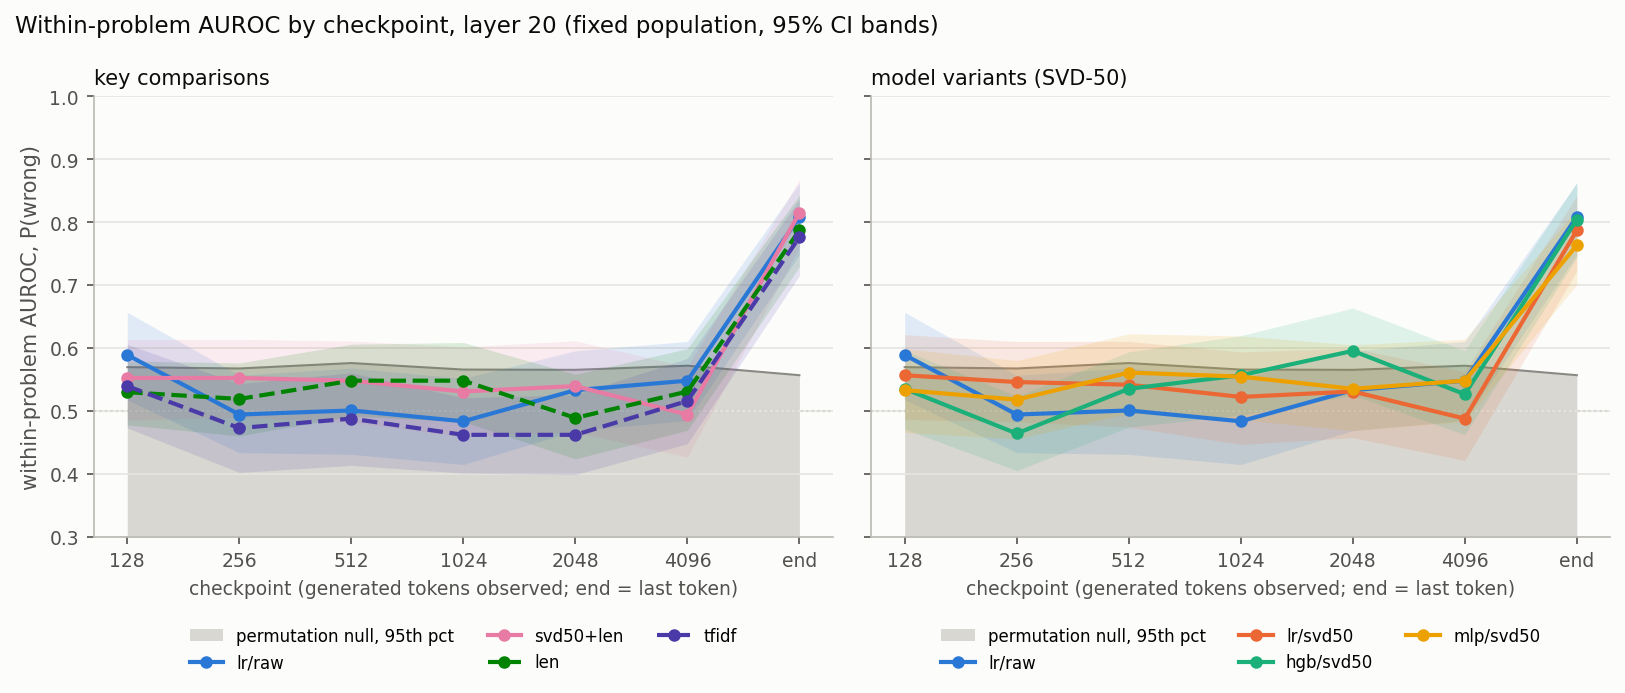

In [ ]:
# P6 results. For dry run, set R = f'{OUT}/quick'
from IPython.display import Image, Markdown, display
R = OUT if os.path.exists(f'{OUT}/summary.md') else f'{OUT}/quick'
display(Markdown(open(f'{R}/summary.md').read()))
display(Image(f'{R}/within_auroc_by_checkpoint.png'))

In [ ]:
# exploratory: checkpoints to 8192, layers 20 16 12
!python -u src/probe_cmp/run.py --out {OUT} --checkpoints 128,256,512,1024,2048,4096,6144,8192,end --layers 20 16 12 --exploratory 2>&1 | tee -a {OUT}/p8192.log

loading and checking every registered acts/meta pair
  source B_fixed: (13219, 9, 1536) float16, layers [-1, 0, 4, 8, 12, 16, 20, 24, 27], 2202 traces, alignment ok
  source BS_end: (636, 9, 1536) float16, layers [-1, 0, 4, 8, 12, 16, 20, 24, 27], 636 traces, alignment ok
excluded 41 truncated traces (trunc or n_gen >= 32768)
fixed population over ['128', '256', '512', '1024', '2048', '4096', '6144', '8192', 'end']: 227 traces, 59 mixed problems, 128 wrong, 192 correct x wrong pairs
secondary, varying population per checkpoint (counts only):
checkpoint  traces  mixed_problems  wrong  correct
       128     599             103    243      356
       256     599             103    243      356
       512     599             103    243      356
      1024     598             103    243      355
      2048     545              97    237      308
      4096     448              87    212      236
      6144     342              74    177      165
      8192     227              59    128   

In [ ]:
# exploratory: checkpoints to 6144, layers 20 16 12
!python -u src/probe_cmp/run.py --out {OUT} --checkpoints 128,256,512,1024,2048,4096,6144,end --layers 20 16 12 --exploratory 2>&1 | tee -a {OUT}/p6144.log

loading and checking every registered acts/meta pair
  source B_fixed: (13219, 9, 1536) float16, layers [-1, 0, 4, 8, 12, 16, 20, 24, 27], 2202 traces, alignment ok
  source BS_end: (636, 9, 1536) float16, layers [-1, 0, 4, 8, 12, 16, 20, 24, 27], 636 traces, alignment ok
excluded 41 truncated traces (trunc or n_gen >= 32768)
fixed population over ['128', '256', '512', '1024', '2048', '4096', '6144', 'end']: 342 traces, 74 mixed problems, 177 wrong, 325 correct x wrong pairs
secondary, varying population per checkpoint (counts only):
checkpoint  traces  mixed_problems  wrong  correct
       128     599             103    243      356
       256     599             103    243      356
       512     599             103    243      356
      1024     598             103    243      355
      2048     545              97    237      308
      4096     448              87    212      236
      6144     342              74    177      165
      8192     227              59    128       99
 

In [ ]:
!python src/probe_cmp/report.py --out {OUT}/L20-16-12/subset_128_256_512_1024_2048_4096_6144_end

## Injection: slip scan (gate 1)

In [ ]:
# slip scan + 40-row audit sample; copies to Drive
!python src/injection/slip_scan.py --tag B --audit 40
!mkdir -p /content/drive/MyDrive/e0_injection && cp data/injection/* /content/drive/MyDrive/e0_injection/

excluded {'truncated': 41}

          traces  claims   slips  per_1k  traces_with_slip  load_bearing  self_corrected  uncorrected  load_bearing_uncorrected  written_is_final_answer  repeats
   wrong     374    7971     140   17.56                56            24              34          106                        17                        3       89
 correct    1787   14616     230   15.74                52            27              21          209                        21                        7       32

slips counted once per (trace, left side, written value); repeats listed separately.
load_bearing = written value reappears later (rewriting the same wrong claim does not count) and did not appear anywhere before the claim, which is stricter than 'reused'.
self_corrected = true value restated within 500 tokens after the claim.
skipped as not a clean claim (wrong): {'expression continues left': 5474, 'expression continues right': 2052, 'modular, base or digit context': 899, 'clock 

In [ ]:
# audit precision from the hand-labelled round-2 sample
import json, pandas as pd
D = '/content/drive/MyDrive/e0_injection'
a = pd.read_csv(f'{D}/audit_B_round2_labeled.csv')
a['lab'] = a['real (y/n)'].astype(str).str.strip().str.lower().str[0]
ok = a[a.lab.isin(['y', 'n'])]
print(f"labeled {len(ok)}/{len(a)}, unsure {(a.lab == '?').sum()}, "
      f"overall precision {(ok.lab == 'y').mean():.2f}")
for col in ['trace_label', 'slip_type', 'context']:
    g = ok.groupby(col).lab
    print(pd.DataFrame({'n': g.size(), 'precision': g.apply(lambda s: (s == 'y').mean()).round(2)}), '\n')

# estimated real slips in the slip-detection pool = pool size x audited precision, per class
s = json.load(open(f'{D}/slip_summary_B.json'))['by_label']
prec = ok.groupby('trace_label').lab.apply(lambda s: (s == 'y').mean())
real = {k: s[k]['detection_pool'] * prec.get(k, float('nan')) for k in ('wrong', 'correct')}
traces = sum(s[k]['detection_pool_traces'] for k in ('wrong', 'correct'))
print({k: round(v) for k, v in real.items()}, f"-> about {sum(real.values()):.0f} real slips "
      f"from {traces} traces (bar: >= 80 slips from >= 40 traces)")

labeled 40/40, unsure 0, overall precision 0.85
              n  precision
trace_label               
correct      20        0.8
wrong        20        0.9 

               n  precision
slip_type                  
close         14       0.93
magnitude      2       1.00
off_by_one     1       1.00
other         14       0.71
single_digit   9       0.89 

              n  precision
context                   
enumeration  11       0.91
main         29       0.83 

{'wrong': 44, 'correct': 34} -> about 78 real slips from 70 traces (bar: >= 80 slips from >= 40 traces)


## Ceiling & r_hat analyses

In [ ]:
# recoverability: r_hat from the Modal ceiling rollouts vs the probes
checkout(BRANCH)
from huggingface_hub import hf_hub_download
OUT = '/content/drive/MyDrive/e0_probe_cmp'
roll = hf_hub_download('MarkSh3n/e0-shared', 'recovery_ceiling', repo_type='dataset')
!python src/probe_cmp/ceiling.py --rollouts {roll} --traces data/traces_B.jsonl --meta data/meta_B.parquet --preds {OUT}/preds --out {OUT}/ceiling

1430 prefixes, 11440 continuations (K per prefix: [8]); torn lines skipped: 10
prefixes per checkpoint: p512 448, p2048 448, p4096 447, t0 87
retokenization drift: 16 of 448 traces
t0 sanity: r(t0) vs the problem's tag-B pass rate over 87 problems, r = 0.69 (mean 0.593 vs 0.540)

r_hat and answer agreement by checkpoint and source trace outcome
checkpoint source trace  prefixes  mean r  r = 0  r = 1  mean agreement  answer boxed in prefix  truncated share  cuts committed  cuts with answer written
     p2048      correct       236   0.721  0.008  0.258           0.721                     0.0            0.034           0.000                     0.339
     p2048        wrong       212   0.419  0.170  0.052           0.154                     0.0            0.046           0.000                     0.288
     p4096      correct       235   0.778  0.017  0.434           0.778                     0.0            0.021           0.089                     0.579
     p4096        wrong       212

### length filter, answer-leak sample

In [ ]:
%%writefile /content/lenfilter.py
# length-filtered r_hat: apply the source traces' selection to every continuation. a
# continuation is kept only if it finished and cut + its length >= 4096, as the 448 source
# traces were (untruncated, >= 4096 tokens). r_hat per prefix over kept continuations; K_eff = 0
# prefixes are dropped. AUROC uses ceiling.compare, so the bootstrap is the one already reported.
#   python lenfilter.py --rollouts R --traces data/traces_B.jsonl --meta data/meta_B.parquet --preds P
import argparse, json, os, sys
import numpy as np
import pandas as pd

ap = argparse.ArgumentParser()
ap.add_argument("--rollouts", required=True)
ap.add_argument("--traces", required=True)
ap.add_argument("--meta", required=True)
ap.add_argument("--preds", required=True)
ap.add_argument("--repo", default=".")
ap.add_argument("--out", default=None, help="optional csv of the per-prefix table")
a = ap.parse_args()
sys.path.insert(0, os.path.join(a.repo, "src", "probe_cmp"))
import ceiling as C  # noqa: E402
import stats as S  # noqa: E402

MAX_NEW, MIN_LEN = 32768, 4096
ORDER = ["t0", "p512", "p2048", "p4096"]
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)

# one row per continuation, deduplicated exactly as ceiling.load_rollouts does
last, torn = {}, 0
for line in open(a.rollouts):
    if not line.strip():
        continue
    try:
        r = json.loads(line)
    except json.JSONDecodeError:
        torn += 1
        continue
    for s in r["samples"]:
        last[(r["prefix_id"], r["round"], s["sample_idx"])] = {
            "prefix_id": r["prefix_id"], "problem_id": r["problem_id"], "trace_id": r["trace_id"],
            "checkpoint": r["checkpoint"], "cut": r["cut_token_idx"], "n_gen": s["n_gen"],
            "finish": s["finish_reason"], "truncated": bool(s["truncated"]), "correct": bool(s["correct"]),
            "think": "</think>" in s["text"]}
cont = pd.DataFrame(list(last.values()))
print(f"{len(cont)} continuations over {cont.prefix_id.nunique()} prefixes; torn lines skipped {torn}")
print("finish_reason:", cont.finish.value_counts(dropna=False).to_dict())
assert not (cont.correct & cont.truncated).any(), "a truncated continuation is scored correct"

cont["finished"] = ~cont.truncated
cont["long_enough"] = cont.cut + cont.n_gen >= MIN_LEN
cont["keep"] = cont.finished & cont.long_enough
cont["k_keep"] = cont.keep & cont.correct

pref = cont.groupby("prefix_id").agg(
    problem_id=("problem_id", "first"), trace_id=("trace_id", "first"), checkpoint=("checkpoint", "first"),
    cut=("cut", "first"), n=("correct", "size"), k=("correct", "sum"), n_fin=("finished", "sum"),
    K_eff=("keep", "sum"), k_eff=("k_keep", "sum")).reset_index()
pref["r"] = pref.k / pref.n
pref["r_finished"] = (pref.k / pref.n_fin.where(pref.n_fin > 0)).fillna(pref.r)  # as ceiling.py
pref["r_len"] = pref.k_eff / pref.K_eff.where(pref.K_eff > 0)

traces = C.load_traces(a.traces)
has = pref.trace_id.notna()
pref["y"] = np.nan
pref.loc[has, "y"] = traces.loc[pref.trace_id[has], "y"].values
pref["label"] = np.where(~has, "t0", np.where(pref.y == 1, "wrong", "correct"))

# same per-prefix n, k and r_finished as the pipeline's own loader
base, _ = C.load_rollouts(a.rollouts)
chk = pref.merge(base[["prefix_id", "n", "k", "r_finished"]], on="prefix_id", suffixes=("", "_c"))
assert len(chk) == len(pref) == len(base), (len(chk), len(pref), len(base))
assert (chk.n == chk.n_c).all() and (chk.k == chk.k_c).all() and np.allclose(chk.r_finished, chk.r_finished_c)
print("per-prefix n, k, r_finished match ceiling.load_rollouts")

# where the other source conditions would bite: vLLM's n_gen counts the EOS on a stop while the
# source's >= 4096 used the retokenized length without it; the source had 32768 tokens in total
# (cut included) and a trace without </think> counted as truncated
meta = C.load_meta(a.meta)
pref["pre_think"] = [isinstance(t, str) and "</think>" in meta.at[(t, int(c)), "prefix"]
                     for t, c in zip(pref.trace_id, pref.cut)]
cont = cont.merge(pref[["prefix_id", "pre_think"]], on="prefix_id")
eos_flip = cont.finished & (cont.long_enough != (cont.cut + cont.n_gen - (cont.finish == "stop") >= MIN_LEN))
over_cap = cont.keep & (cont.cut + cont.n_gen >= MAX_NEW)
no_think = cont.keep & ~(cont.think | cont.pre_think)
print(f"kept continuations: {int(cont.keep.sum())}; whose keep flips if the EOS is not counted: "
      f"{int(eos_flip.sum())}")
print("kept but outside the source's other rules, by checkpoint:")
print(pd.DataFrame({"kept": cont.groupby("checkpoint").keep.sum(),
                    "cut + n_gen >= 32768": over_cap.groupby(cont.checkpoint).sum(),
                    "no </think> in prefix or continuation": no_think.groupby(cont.checkpoint).sum()})
      .reindex(ORDER).to_string())
cont["strict"] = cont.keep & ~over_cap & ~no_think
st = cont.groupby("prefix_id").agg(K_strict=("strict", "sum"),
                                   k_strict=("correct", lambda v: int((v & cont.loc[v.index, "strict"]).sum())))
pref = pref.merge(st, on="prefix_id")
pref["r_strict"] = pref.k_strict / pref.K_strict.where(pref.K_strict > 0)

print("\n== continuations removed, and prefixes dropped at K_eff = 0 ==")
cont["label"] = cont.prefix_id.map(pref.set_index("prefix_id").label)
rem = cont.groupby(["checkpoint", "label"]).agg(
    continuations=("keep", "size"), truncated=("truncated", "sum"),
    finished_but_short=("long_enough", lambda v: int((~v & cont.loc[v.index, "finished"]).sum())),
    kept=("keep", "sum"))
drop = pref.groupby(["checkpoint", "label"]).agg(
    prefixes=("K_eff", "size"), dropped=("K_eff", lambda v: int((v == 0).sum())),
    dropped_all_truncated=("n_fin", lambda v: int((v == 0).sum())),
    mean_K_eff=("K_eff", "mean"))
drop["dropped_finished_but_short"] = drop.dropped - drop.dropped_all_truncated
print(rem.join(drop).reindex(ORDER, level=0).round(2).to_string())

kept = pref[pref.K_eff > 0]
tr = kept[kept.label != "t0"]
print("\n== (a) mean r_hat by source label, kept prefixes ==")
print(tr.groupby(["checkpoint", "label"]).agg(
    prefixes=("r_len", "size"), r_len=("r_len", "mean"), r_finished_same_prefixes=("r_finished", "mean"),
    r_unfiltered_same_prefixes=("r", "mean")).reindex(ORDER[1:], level=0).round(3).to_string())

pop = sorted(pref.trace_id.dropna().unique())
acc_all = 1 - traces.loc[pop, "y"].mean()
print(f"\n== (b) mean r_hat over traces vs source accuracy ({len(pop)} traces, accuracy {acc_all:.3f}) ==")


def paired_ci(d, groups):
    # problem-clustered bootstrap of a per-trace mean, 2000 draws, seed 0
    g = pd.Series(d).groupby(np.asarray(groups))
    sums, cnts = g.sum().values, g.size().values
    draws = S.problem_draws(len(sums), 2000, seed=0)
    return S.ci(draws @ sums / (draws @ cnts))


rows = []
for c in ORDER[1:]:
    allc, g = pref[pref.checkpoint == c], tr[tr.checkpoint == c]
    d = g.r_len.values - (1 - g.y.values)
    lo, hi = paired_ci(d, g.problem_id.values)
    gs = allc[allc.K_strict > 0]
    rows.append({"checkpoint": c, "traces": len(allc), "kept": len(g), "mean r_len": g.r_len.mean(),
                 "source acc, kept": 1 - g.y.mean(), "r_len - acc (paired)": d.mean(), "CI low": lo, "CI high": hi,
                 "mean r_finished, all": allc.r_finished.mean(), "mean r, all": allc.r.mean(),
                 "mean r_strict": gs.r_strict.mean(), "source acc, strict kept": 1 - gs.y.mean()})
# t0 is per problem: weight each problem by its traces in the population
w = traces.loc[pop].groupby("problem_id").size()
t0 = pref[pref.checkpoint == "t0"].set_index("problem_id")
t0k = t0[t0.K_eff > 0]
acc_p = 1 - traces.loc[pop].groupby("problem_id").y.mean()
rows.append({"checkpoint": "t0 (trace-weighted)", "traces": int(w.loc[t0.index].sum()),
             "kept": int(w.loc[t0k.index].sum()),
             "mean r_len": float((t0k.r_len * w.loc[t0k.index]).sum() / w.loc[t0k.index].sum()),
             "source acc, kept": float((acc_p.loc[t0k.index] * w.loc[t0k.index]).sum() / w.loc[t0k.index].sum()),
             "mean r_finished, all": float((t0.r_finished * w.loc[t0.index]).sum() / w.loc[t0.index].sum()),
             "mean r, all": float((t0.r * w.loc[t0.index]).sum() / w.loc[t0.index].sum())})
print(pd.DataFrame(rows).round(3).to_string(index=False))

print("\n== (c) within-problem AUROC, P(wrong); r_hat score = 1 - r_hat; deltas paired on the same problem draws ==")
out = []
for rc, pc in C.CKPTS.items():
    g = tr[tr.checkpoint == rc][["trace_id", "problem_id", "y", "r", "r_finished", "r_len"]].copy()
    g["y"] = g.y.astype(int)
    preds = C.load_preds(os.path.join(a.preds, f"{pc}.parquet"))
    # compare() scores the columns r and r_finished: the first call puts the unfiltered r_hat in
    # the r_finished slot, the second the usual r_finished. every delta is length-filtered minus
    # the row's score, on the same traces and the same problem draws
    one, ties = C.compare(g.assign(r=g.r_len, r_finished=g.r), preds)
    two, _ = C.compare(g.assign(r=g.r_len), preds)
    rows_c = pd.concat([one[one.score == "r_hat"].assign(score="r_hat length-filtered"),
                        one[one.score == "r_hat finished"].assign(score="r_hat unfiltered"),
                        two[two.score == "r_hat finished"],
                        one[one.score.isin(["lr/raw L20", "len"])]])
    for r in rows_c.itertuples():
        out.append({"checkpoint": pc, "score": r.score, "AUROC": f"{r.auroc:.3f} [{r.ci_low:.3f}, {r.ci_high:.3f}]",
                    "length-filtered minus score": "–" if r.score == "r_hat length-filtered" else
                    f"{r.delta_r_hat_minus:+.3f} [{r.delta_ci_low:+.3f}, {r.delta_ci_high:+.3f}] p={r.delta_p:.3f}",
                    "traces/problems/pairs": f"{r.n_traces}/{r.n_problems}/{r.n_pairs}"})
    out.append({"checkpoint": pc, "score": f"(pairs tied under length-filtered r_hat: {ties:.2f})"})
print(pd.DataFrame(out).fillna("").to_string(index=False))

g4 = pref[pref.checkpoint == "p4096"]
k4 = g4[g4.K_eff > 0]
print(f"\n4096 check: length condition failed by {int((~cont[cont.checkpoint == 'p4096'].long_enough).sum())} "
      f"continuations; {int((g4.K_eff == 0).sum())} prefixes dropped; max |r_len - r_finished| on kept "
      f"{float((k4.r_len - k4.r_finished).abs().max()):.2e}")
if a.out:
    pref.to_csv(a.out, index=False)
    print("wrote", a.out)

Writing /content/lenfilter.py


In [ ]:
%%writefile /content/leak_sample.py
# 20 random p512 cuts that the answer-value filter removes, with every place the source trace's
# final answer matches in the cut, for hand-labelling: stated answer / intermediate result /
# incidental number match. uses ceiling.answer_flags and its exact regex.
#   python leak_sample.py --rollouts R --traces data/traces_B.jsonl --meta data/meta_B.parquet
import argparse, json, os, re, sys
import numpy as np

ap = argparse.ArgumentParser()
ap.add_argument("--rollouts", required=True)
ap.add_argument("--traces", required=True)
ap.add_argument("--meta", required=True)
ap.add_argument("--repo", default=".")
ap.add_argument("--n", type=int, default=20)
ap.add_argument("--seed", type=int, default=0)
ap.add_argument("--pos", type=int, default=512)
a = ap.parse_args()
sys.path.insert(0, os.path.join(a.repo, "src", "probe_cmp"))
import ceiling as C  # noqa: E402

ids = set()
for line in open(a.rollouts):
    try:
        r = json.loads(line)
    except json.JSONDecodeError:
        continue
    if r["checkpoint"] == f"p{a.pos}":
        ids.add(r["trace_id"])
ids = sorted(ids)
traces = C.load_traces(a.traces)
meta = C.load_meta(a.meta)


def clean(s):
    return re.sub(r"\\(left|right)", "", s).replace("\\dfrac", "\\frac").replace("\\tfrac", "\\frac")


flags = {t: C.answer_flags(meta.at[(t, a.pos), "prefix"], traces.at[t, "answer"]) for t in ids}
removed = [t for t in ids if flags[t][1]]
print(f"p{a.pos}: {len(removed)} of {len(ids)} cuts removed by the answer-value filter "
      f"({sum(flags[t][0] for t in ids)} of them committed: </think> or \\boxed in the cut)")
pick = sorted(np.random.default_rng(a.seed).choice(removed, min(a.n, len(removed)), replace=False),
              key=lambda t: (traces.at[t, "problem_id"], t))
for i, t in enumerate(pick, 1):
    ans = traces.at[t, "answer"]
    pat = rf"(?<![\w.]){re.escape(C.norm(ans))}(?!\w|\.\d)"
    text = clean(meta.at[(t, a.pos), "prefix"])
    hits = [m.span() for m in re.finditer(pat, text)]
    prob = traces.at[t, "problem"]
    show = sorted({0, len(hits) - 1} | ({1} if len(hits) > 2 else set()))
    print(f"\n=== {i}. {t} | source {'wrong' if traces.at[t, 'y'] else 'correct'} | gold {traces.at[t, 'gold']!r} | "
          f"source answer {ans!r} -> matched as {C.norm(ans)!r} | {len(hits)} hit(s) in the cut | "
          f"answer value in the problem statement: {bool(re.search(pat, clean(prob)))}")
    print("  problem:", " ".join(prob.split())[:300])
    for j in show:
        s, e = hits[j]
        ctx = text[max(0, s - 180):s] + " >>" + text[s:e] + "<< " + text[e:e + 100]
        print(f"  hit {j + 1}/{len(hits)} @ char {s}: ..." + ctx.replace("\n", " / ") + "...")

Writing /content/leak_sample.py


In [ ]:
# CPU only, no model: length-filtered r_hat (a)-(c), then the 20 answer-filter samples at 512
%cd /content/Ghait---MJJS
from huggingface_hub import hf_hub_download
roll = hf_hub_download('MarkSh3n/e0-shared', 'recovery_ceiling', repo_type='dataset')
OUT = '/content/drive/MyDrive/e0_probe_cmp'
!python /content/lenfilter.py --rollouts {roll} --traces data/traces_B.jsonl --meta data/meta_B.parquet --preds {OUT}/preds --out {OUT}/ceiling/lenfilter_prefixes.csv
!python /content/leak_sample.py --rollouts {roll} --traces data/traces_B.jsonl --meta data/meta_B.parquet

/content/Ghait---MJJS
11440 continuations over 1430 prefixes; torn lines skipped 10
finish_reason: {'stop': 10997, 'length': 443}
per-prefix n, k, r_finished match ceiling.load_rollouts
kept continuations: 10503; whose keep flips if the EOS is not counted: 0
kept but outside the source's other rules, by checkpoint:
            kept  cut + n_gen >= 32768  no </think> in prefix or continuation
checkpoint                                                                   
t0           589                     0                                      0
p512        3190                     7                                      0
p2048       3282                    25                                      1
p4096       3442                    35                                      2

== continuations removed, and prefixes dropped at K_eff = 0 ==
                    continuations  truncated  finished_but_short  kept  prefixes  dropped  dropped_all_truncated  mean_K_eff  dropped_finished_but_shor

### temperature per generation block

In [ ]:
%%writefile /content/temp_blocks.py
# MLE of the sampling temperature behind traces_B, per generation block. the notebook shows the
# pilot resuming with "8/80 problems left" under --temp 0.7, so lines 0-431 (72 problems) come from
# an earlier invocation whose flags are not on record (generate.py's default --temp is 0.6),
# lines 432-479 from that visible --temp 0.7 resume, and 480+ from run_bg gen_B ... --temp 0.7.
# teacher-forced under vLLM's sampler (logits / T, then top-p 0.95), check_temp.py's scoring.
# traces are spread evenly over each block's lines, so a sub-block at another T cannot hide.
#   python temp_blocks.py --traces data/traces_B.jsonl [--n 20] [--out temp_blocks.json]
import argparse, json, os, sys
import numpy as np
import torch

ap = argparse.ArgumentParser()
ap.add_argument("--traces", required=True)
ap.add_argument("--repo", default=".")
ap.add_argument("--n", type=int, default=20, help="traces per block")
ap.add_argument("--max-tokens-per-trace", type=int, default=4096)
ap.add_argument("--out", default=None)
a = ap.parse_args()
sys.path.insert(0, os.path.join(a.repo, "src", "recovery"))
from common import MAX_NEW, MODEL, TOP_P, canonical, encode_trace, load_tokenizer, prompt_ids  # noqa: E402
from check_temp import trace_curves  # noqa: E402
from transformers import AutoModelForCausalLM  # noqa: E402

temps = np.round(np.arange(0.30, 1.2 + 1e-9, 0.01), 2)  # the grid estimate_temp.py used
i6, i7 = int(np.abs(temps - 0.6).argmin()), int(np.abs(temps - 0.7).argmin())
traces = [json.loads(line) for line in open(a.traces)]
assert len(traces) == 2202, len(traces)
blocks = {"lines 0-431": range(0, 432), "lines 432-479": range(432, 480), "lines 480+": range(480, len(traces))}
for name, rng_ in blocks.items():
    pids = [traces[i]["problem_id"] for i in rng_]
    print(f"{name}: {len(rng_)} traces, {len(set(pids))} problems, problem_id {pids[0]}..{pids[-1]}", flush=True)
# a block boundary must not split a problem's 6 samples
for b in (432, 480):
    assert traces[b - 1]["problem_id"] != traces[b]["problem_id"], f"line {b} splits a problem"

tok = load_tokenizer()
model = AutoModelForCausalLM.from_pretrained(MODEL, torch_dtype=torch.float16).to("cuda").eval()
rng = np.random.default_rng(0)
print(f"\ngrid {temps[0]}..{temps[-1]}, top_p {TOP_P}, <= {a.max_tokens_per_trace} tokens per trace", flush=True)
results = {}
for name, lines in blocks.items():
    pool = [i for i in lines if not traces[i]["trunc"] and traces[i]["n_gen"] < MAX_NEW]
    starts = np.unique(np.linspace(0, len(pool), min(a.n, len(pool)), endpoint=False).astype(int))
    taken, rows, nuc, plain = set(), [], [], []
    for s in starts:
        for j in range(s, len(pool)):  # first canonical trace at or after the slot
            i = pool[j]
            if i in taken:
                continue
            t = traces[i]
            ids, _ = encode_trace(tok, t["text"])
            if canonical(t, ids):
                break
        else:
            continue
        taken.add(i)
        ids = ids[: a.max_tokens_per_trace]
        x, y, _ = trace_curves(model, "cuda", prompt_ids(tok, t["problem"]), ids, temps, TOP_P, 256)
        nuc.append(x), plain.append(y)
        rows.append({"line": i, "trace_id": t["trace_id"], "tokens": len(ids), "t_hat": float(temps[x.argmax()]),
                     "dlogL_07_minus_06": float(x[i7] - x[i6])})
        print(f"  {name} {len(rows):>2} line {i:>4} {t['trace_id']:>7} {len(ids):>5} tok | T_hat {temps[x.argmax()]:.2f} "
              f"| logL(0.7)-logL(0.6) {x[i7] - x[i6]:+8.1f}", flush=True)
    nuc, plain = np.array(nuc), np.array(plain)
    boots = [temps[nuc[rng.integers(0, len(nuc), len(nuc))].sum(0).argmax()] for _ in range(2000)]
    d = nuc[:, i7] - nuc[:, i6]
    results[name] = {"traces": len(rows), "tokens": int(sum(r["tokens"] for r in rows)),
                     "t_hat": float(temps[nuc.sum(0).argmax()]), "ci": [float(v) for v in np.percentile(boots, [2.5, 97.5])],
                     "t_hat_no_top_p": float(temps[plain.sum(0).argmax()]), "dlogL_07_minus_06": float(d.sum()),
                     "traces_favouring_07": int((d > 0).sum()), "per_trace": rows}

print("\nblock          traces  tokens  T_hat [95% CI]       no-top-p T_hat  logL(0.7)-logL(0.6)  traces favouring 0.7")
for name, r in results.items():
    print(f"{name:<14} {r['traces']:>6} {r['tokens']:>7}  {r['t_hat']:.2f} [{r['ci'][0]:.2f}, {r['ci'][1]:.2f}]"
          f"   {r['t_hat_no_top_p']:>13.2f}  {r['dlogL_07_minus_06']:>+19.1f}  {r['traces_favouring_07']:>6}/{r['traces']}")
if a.out:
    json.dump(results, open(a.out, "w"), indent=1)
    print("wrote", a.out)

Writing /content/temp_blocks.py


In [ ]:
# T4 GPU: per-block temperature of the source traces (teacher-forced scoring, no generation; ~20-40 min)
%cd /content/Ghait---MJJS
OUT = '/content/drive/MyDrive/e0_probe_cmp'
!python -u /content/temp_blocks.py --traces data/traces_B.jsonl --out {OUT}/temp_blocks.json

/content/Ghait---MJJS
lines 0-431: 432 traces, 72 problems, problem_id 1..320
lines 432-479: 48 traces, 8 problems, problem_id 322..366
lines 480+: 1722 traces, 287 problems, problem_id 0..364


grid 0.3..1.2, top_p 0.95, <= 4096 tokens per trace
  lines 0-431  1 line    0     1_0  1943 tok | T_hat 0.69 | logL(0.7)-logL(0.6)    +39.4
  lines 0-431  2 line   20    11_2  3192 tok | T_hat 0.70 | logL(0.7)-logL(0.6)   +129.6
  lines 0-431  3 line   41    54_5  4096 tok | T_hat 0.70 | logL(0.7)-logL(0.6)   +101.5
  lines 0-431  4 line   61    84_1  2311 tok | T_hat 0.70 | logL(0.7)-logL(0.6)    +70.0
  lines 0-431  5 line   82    98_4  4096 tok | T_hat 0.70 | logL(0.7)-logL(0.6)   +319.2
  lines 0-431  6 line  102   109_0  4096 tok | T_hat 0.68 | logL(0.7)-logL(0.6)   +104.6
  lines 0-431  7 line  125   121_5  4096 tok | T_hat 0.71 | logL(0.7)-logL(0.6)   +127.3
  lines 0-431  8 line  146   135_2  4096 tok | T_hat 0.70 | logL(0.7)-logL(0.6)   +255.6
  lines 0-431  9 line  168   142_0  4096 

### BOS check

In [ ]:
%%writefile /content/bos_check.py
# which prompt generated the source traces: one BOS or two. the source prompt ids were never stored.
# the template text is fixed (the model's tokenizer_config last changed 2025-02-09), so only the
# leading BOS can differ: vLLM tokenizes a string prompt with special tokens on, and whether that
# adds a second BOS depends on the transformers version (5.x loads Qwen2Tokenizer and adds none).
# the rollouts were built with two (build_prefixes asserts it; run_rollouts checks vLLM agrees).
# teacher-forced: the variant that generated a trace has the higher expected log-likelihood.
#   python bos_check.py --prefixes <lenfilter_prefixes.csv> --traces data/traces_B.jsonl
import argparse, json, os, sys
import numpy as np
import pandas as pd
import torch
import transformers
from scipy.stats import binomtest

ap = argparse.ArgumentParser()
ap.add_argument("--prefixes", required=True, help="lenfilter.py's per-prefix csv: the 448 population traces")
ap.add_argument("--traces", required=True)
ap.add_argument("--repo", default=".")
ap.add_argument("--n", type=int, default=30, help="traces per generation block")
ap.add_argument("--max-tokens-per-trace", type=int, default=2048)
ap.add_argument("--out", default=None)
a = ap.parse_args()
sys.path.insert(0, os.path.join(a.repo, "src", "recovery"))
from common import MODEL, TOP_P, build_prompt, canonical, encode_trace, load_tokenizer  # noqa: E402
from check_temp import trace_curves  # noqa: E402
from transformers import AutoModelForCausalLM  # noqa: E402

T = 0.7
tok = load_tokenizer()
bos = tok.bos_token_id
traces = [json.loads(line) for line in open(a.traces)]
line_of = {t["trace_id"]: i for i, t in enumerate(traces)}
pop = sorted(set(pd.read_csv(a.prefixes).trace_id.dropna()), key=line_of.get)
probe = build_prompt(tok, traces[line_of[pop[0]]]["problem"])
head = tok(probe)["input_ids"][:3]
print(f"this env: transformers {transformers.__version__}, {type(tok).__name__}; default tokenization of a "
      f"prompt opens {head} -> {sum(1 for x in head[:2] if x == bos)} BOS (bos id {bos})", flush=True)


def variants(problem):
    one = tok(build_prompt(tok, problem), add_special_tokens=False)["input_ids"]
    assert one[0] == bos and one[1] != bos, one[:3]  # the template text itself carries one BOS
    return {"one BOS": one, "two BOS": [bos] + one}


blocks = {"lines 0-431": (0, 432), "lines 432-479": (432, 480), "lines 480+": (480, len(traces))}
model = AutoModelForCausalLM.from_pretrained(MODEL, torch_dtype=torch.float16).to("cuda").eval()
rows = []
for name, (lo, hi) in blocks.items():
    cand = [t for t in pop if lo <= line_of[t] < hi]
    picked = 0
    for j in np.unique(np.linspace(0, len(cand), min(a.n * 2, len(cand)), endpoint=False).astype(int)):
        if picked == a.n:
            break
        t = traces[line_of[cand[j]]]
        ids, _ = encode_trace(tok, t["text"])
        if not canonical(t, ids):
            continue
        ids = ids[: a.max_tokens_per_trace]
        r = {"block": name, "line": line_of[t["trace_id"]], "trace_id": t["trace_id"], "tokens": len(ids)}
        for v, p_ids in variants(t["problem"]).items():
            nuc, plain, out = trace_curves(model, "cuda", p_ids, ids, np.array([T]), TOP_P, 256)
            r[f"nuc {v}"], r[f"plain {v}"], r[f"outside {v}"] = float(nuc[0]), float(plain[0]), int(out[0])
        r["d_nuc"] = r["nuc two BOS"] - r["nuc one BOS"]
        r["d_plain"] = r["plain two BOS"] - r["plain one BOS"]
        rows.append(r)
        picked += 1
        print(f"  {name} {picked:>2} line {r['line']:>4} {r['trace_id']:>7} {len(ids):>5} tok | "
              f"logL(two BOS) - logL(one BOS): top-p {r['d_nuc']:+8.2f}, no top-p {r['d_plain']:+8.2f}", flush=True)

df = pd.DataFrame(rows)
print("\nlogL(two BOS) - logL(one BOS) at T=0.7; positive favours two BOS (the rollouts' prompt)")
summ = []
for name, g in list(df.groupby("block", sort=False)) + [("all", df)]:
    k = int((g.d_nuc > 0).sum())
    summ.append({"block": name, "traces": len(g), "tokens": int(g.tokens.sum()), "sum d (top-p)": g.d_nuc.sum(),
                 "per token": g.d_nuc.sum() / g.tokens.sum(), "sum d (no top-p)": g.d_plain.sum(),
                 "traces favouring two BOS": f"{k}/{len(g)}",
                 "sign test p": binomtest(k, len(g)).pvalue if len(g) else np.nan})
print(pd.DataFrame(summ).round(4).to_string(index=False))
if a.out:
    df.to_csv(a.out, index=False)
    print("wrote", a.out)

Writing /content/bos_check.py


In [ ]:
# T4 GPU, teacher-forced (no generation; a few minutes): did the source prompts carry one BOS or two?
%cd /content/Ghait---MJJS
OUT = '/content/drive/MyDrive/e0_probe_cmp'
!python -u /content/bos_check.py --prefixes {OUT}/ceiling/lenfilter_prefixes.csv --traces data/traces_B.jsonl --out {OUT}/ceiling/bos_check.csv

/content/Ghait---MJJS
this env: transformers 5.18.0, Qwen2Tokenizer; default tokenization of a prompt opens [151646, 151644, 2082] -> 1 BOS (bos id 151646)
  lines 0-431  1 line   36    54_0  2048 tok | logL(two BOS) - logL(one BOS): top-p    -8.86, no top-p    -2.13
  lines 0-431  2 line   38    54_2  2048 tok | logL(two BOS) - logL(one BOS): top-p    -9.51, no top-p    -2.68
  lines 0-431  3 line   41    54_5  2048 tok | logL(two BOS) - logL(one BOS): top-p    -9.88, no top-p    -2.97
  lines 0-431  4 line   44    55_2  2048 tok | logL(two BOS) - logL(one BOS): top-p   -19.12, no top-p    +1.40
  lines 0-431  5 line   46    55_4  2048 tok | logL(two BOS) - logL(one BOS): top-p    -1.70, no top-p    -1.53
  lines 0-431  6 line   49    69_1  2048 tok | logL(two BOS) - logL(one BOS): top-p    -6.73, no top-p    -0.06
  lines 0-431  7 line   54    81_0  2048 tok | logL(two BOS) - logL(one BOS): top-p    -3.26, no top-p    -3.44
  lines 0-431  8 line   56    81_2  2048 tok | logL(two BOS)

### mixed-problem selection

In [ ]:
%%writefile /content/mixed_sel.py
# mixed-problem selection. the population keeps a problem only if its eligible traces (untruncated,
# n_gen < 32768, retokenized length >= 4096: build_prefixes.ceiling_population, the same set as
# probe_cmp's) hold a correct and a wrong one. with per-trace accuracy p among eligible traces and
# n of them, E[source accuracy | mixed] = (p - p^n) / (1 - p^n - (1-p)^n). p_hat per problem comes
# from the t0 rollouts, length-filtered like the source (lenfilter.py's r_len at t0).
#   python mixed_sel.py --prefixes <lenfilter_prefixes.csv> --traces data/traces_B.jsonl
import argparse, json, os, sys
import numpy as np
import pandas as pd

ap = argparse.ArgumentParser()
ap.add_argument("--prefixes", required=True, help="lenfilter.py's per-prefix csv")
ap.add_argument("--traces", required=True)
ap.add_argument("--repo", default=".")
ap.add_argument("--skip-rebuild", action="store_true", help="skip re-deriving the population (needs the tokenizer)")
ap.add_argument("--out", default=None, help="optional per-problem csv")
a = ap.parse_args()
sys.path.insert(0, os.path.join(a.repo, "src", "probe_cmp"))
import stats as S  # noqa: E402

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
CUTS = ["p512", "p2048", "p4096"]
pref = pd.read_csv(a.prefixes)
traces = [json.loads(line) for line in open(a.traces)]
T = pd.DataFrame(traces).set_index("trace_id", drop=False).rename_axis(None)
pop_ids = set(pref.trace_id.dropna())
pop = T.loc[sorted(pop_ids)]
print(f"population from the rollouts: {len(pop)} traces, {pop.problem_id.nunique()} problems")

if not a.skip_rebuild:
    sys.path.insert(0, os.path.join(a.repo, "src", "recovery"))
    from build_prefixes import CEILING_POSITIONS, ceiling_population  # noqa: E402
    from common import MAX_NEW, encode_trace, load_tokenizer  # noqa: E402
    tok = load_tokenizer()
    # exactly build_ceiling's lens
    lens = {t["trace_id"]: len(encode_trace(tok, t["text"])[0]) if not t["trunc"] and t["n_gen"] < MAX_NEW else 0
            for t in traces}
    rebuilt = ceiling_population(traces, lens, max(CEILING_POSITIONS))
    got = {t["trace_id"] for ts in rebuilt.values() for t in ts}
    assert got == pop_ids, f"rebuilt population differs: {len(got ^ pop_ids)} traces"
    elig = T[[lens[t] >= max(CEILING_POSITIONS) for t in T.index]]
    g6 = T.groupby("problem_id").is_correct.agg(["min", "max"])
    mixed6 = set(g6.index[g6["min"] != g6["max"]])
    has_elig = set(elig.problem_id)
    print(f"ceiling_population rebuilt from traces_B gives the same {len(got)} traces: mixed is taken over "
          f"eligible traces only.\n  problems with >= 1 eligible trace: {len(has_elig)}; mixed over eligible: "
          f"{len(rebuilt)}; mixed over all 6 samples: {len(mixed6 & has_elig)} of them ({len(mixed6)} of 367 overall)")

n = pop.groupby("problem_id").size()
acc = pop.groupby("problem_id").is_correct.mean()
t0 = pref[pref.checkpoint == "t0"].set_index("problem_id").loc[n.index]
assert (t0.K_eff > 0).all()
p_len, p_unf = t0.k_eff / t0.K_eff, t0.k / t0.n


def f(p, n):
    # E[accuracy | 1 <= correct <= n-1]; limits at p = 0 (1/n) and p = 1 ((n-1)/n)
    p, n = np.asarray(p, float), np.asarray(n, float)
    den = 1 - p ** n - (1 - p) ** n
    with np.errstate(invalid="ignore", divide="ignore"):
        v = (p - p ** n) / den
    return np.where(p <= 0, 1 / n, np.where(p >= 1, (n - 1) / n, v))


def f_post(k, K, n, draws=4000, seed=0):
    # f averaged over a Jeffreys Beta(k + 1/2, K - k + 1/2) posterior for p: p_hat has K <= 8 samples
    rng = np.random.default_rng(seed)
    return np.array([f(rng.beta(ki + 0.5, Ki - ki + 0.5, draws), ni).mean() for ki, Ki, ni in zip(k, K, n)])


prob = pd.DataFrame({"n_eligible": n, "source_acc": acc, "p_hat": p_len, "K_eff_t0": t0.K_eff,
                     "pred": f(p_len, n), "pred_posterior": f_post(t0.k_eff, t0.K_eff, n),
                     "pred_unfiltered_p": f(p_unf, n), "pred_n6": f(p_len, 6)})
rr = (pref[pref.checkpoint.isin(CUTS)].pivot(index="trace_id", columns="checkpoint", values="r_len")
      .reindex(columns=CUTS))
tr = pop[["problem_id", "is_correct"]].join(rr)
for c in CUTS:
    prob[f"r_{c}"] = tr.groupby("problem_id")[c].mean()
print("n eligible per problem:", n.value_counts().sort_index().to_dict())


def wmean(col, sub):
    return float((sub[col] * sub.n_eligible).sum() / sub.n_eligible.sum())


def ci(sub, num):
    # problem-clustered bootstrap of a trace-weighted mean of per-problem values, 2000 draws, seed 0
    draws = S.problem_draws(len(sub), 2000, seed=0)
    w = sub.n_eligible.values
    return S.ci(draws @ (w * num) / (draws @ w))


def report(sub, name):
    obs, pred = wmean("source_acc", sub), wmean("pred", sub)
    lo, hi = ci(sub, (sub.source_acc - sub.pred).values)
    row = {"problems": f"{name}: {len(sub)}", "traces": int(sub.n_eligible.sum()), "source acc": obs,
           "predicted | mixed": pred, "obs - pred": obs - pred, "CI": f"[{lo:+.3f}, {hi:+.3f}]",
           "pred (posterior)": wmean("pred_posterior", sub), "pred (unfiltered p)": wmean("pred_unfiltered_p", sub),
           "pred (n=6)": wmean("pred_n6", sub), "mean p_hat (t0)": wmean("p_hat", sub)}
    for c in CUTS:
        sub_t = tr[tr.problem_id.isin(sub.index)]
        g = sub_t.assign(d=sub_t[c] - sub_t.is_correct.astype(float)).groupby("problem_id").d.mean()
        d_lo, d_hi = ci(sub, g.loc[sub.index].values)
        row[f"r {c[1:]}"] = wmean(f"r_{c}", sub)
        row[f"r {c[1:]} - acc"] = f"{wmean(f'r_{c}', sub) - obs:+.3f} [{d_lo:+.3f}, {d_hi:+.3f}]"
    return row


bands = [("all", prob), ("p_hat in [0.35, 0.65]", prob[(prob.p_hat >= 0.35) & (prob.p_hat <= 0.65)]),
         ("p_hat < 0.35", prob[prob.p_hat < 0.35]), ("p_hat > 0.65", prob[prob.p_hat > 0.65])]
rows = [report(sub, name) for name, sub in bands if len(sub)]
out = pd.DataFrame(rows).set_index("problems")
print("\n== source accuracy vs its prediction under mixed selection, and mean r_hat (trace-weighted) ==")
print(out[["traces", "source acc", "predicted | mixed", "obs - pred", "CI", "mean p_hat (t0)"]].round(3).to_string())
print("\nsensitivity of the prediction:")
print(out[["pred (posterior)", "pred (unfiltered p)", "pred (n=6)"]].round(3).to_string())
print("\nmean length-filtered r_hat at each cut, and r_hat - source acc (paired, problem bootstrap):")
print(out[[c for c in out.columns if c.startswith("r ")]].round(3).to_string())
al = out.iloc[0]
print(f"\nshare of the t0 gap (mean p_hat - source acc = {al['mean p_hat (t0)'] - al['source acc']:+.3f}) that "
      f"selection predicts: {(al['mean p_hat (t0)'] - al['predicted | mixed']) / (al['mean p_hat (t0)'] - al['source acc']):.0%}")
print("note: inside a p_hat band, mean p_hat (t0) is selected on its own noise; the r columns use other rollouts")
if a.out:
    prob.to_csv(a.out)
    print("wrote", a.out)

Writing /content/mixed_sel.py


In [ ]:
# CPU only (tokenizer, no model): mixed-problem selection check against source accuracy 0.527
%cd /content/Ghait---MJJS
OUT = '/content/drive/MyDrive/e0_probe_cmp'
!python /content/mixed_sel.py --prefixes {OUT}/ceiling/lenfilter_prefixes.csv --traces data/traces_B.jsonl --out {OUT}/ceiling/mixed_sel_problems.csv

/content/Ghait---MJJS
population from the rollouts: 448 traces, 87 problems
ceiling_population rebuilt from traces_B gives the same 448 traces: mixed is taken over eligible traces only.
  problems with >= 1 eligible trace: 250; mixed over eligible: 87; mixed over all 6 samples: 102 of them (106 of 367 overall)
n eligible per problem: {2: 5, 3: 5, 4: 12, 5: 15, 6: 50}

== source accuracy vs its prediction under mixed selection, and mean r_hat (trace-weighted) ==
                           traces  source acc  predicted | mixed  obs - pred                CI  mean p_hat (t0)
problems                                                                                                       
all: 87                       448       0.527              0.566      -0.039  [-0.079, -0.000]            0.600
p_hat in [0.35, 0.65]: 30     155       0.484              0.515      -0.031  [-0.110, +0.049]            0.521
p_hat < 0.35: 18               92       0.304              0.284       0.020  [-0.048,

In [ ]:
# CPU, no model: which of the 87 problems are pilot problems (one-BOS source prompt), and the
# existing raw-p_hat selection residual split by generation block. a problem's 6 traces never span blocks.
%cd /content/Ghait---MJJS
import json, pandas as pd
OUT = '/content/drive/MyDrive/e0_probe_cmp'
line = {json.loads(l)['trace_id']: i for i, l in enumerate(open('data/traces_B.jsonl'))}
prob = pd.read_csv(f'{OUT}/ceiling/mixed_sel_problems.csv', index_col=0)
pref = pd.read_csv(f'{OUT}/ceiling/lenfilter_prefixes.csv')
pop = pref.dropna(subset=['trace_id']).drop_duplicates('trace_id')
blk = pop.groupby('problem_id').trace_id.agg(lambda ts: {line[t] < 480 for t in ts})
assert (blk.map(len) == 1).all(), 'a problem spans the pilot and the main run'
prob['block'] = blk.map(lambda s: 'pilot, lines 0-479 (one BOS)' if s.pop() else 'main, lines 480+ (two BOS)')
w = lambda g, c: (g[c] * g.n_eligible).sum() / g.n_eligible.sum()
rows = []
for name, g in list(prob.groupby('block')) + [('all', prob)]:
    hi = g[g.p_hat > 0.65]
    rows.append({'block': name, 'problems': len(g), 'traces': int(g.n_eligible.sum()), 'source acc': w(g, 'source_acc'),
                 'pred (raw p_hat)': w(g, 'pred'), 'obs - pred': w(g, 'source_acc') - w(g, 'pred'), 'mean p_hat': w(g, 'p_hat'),
                 'p_hat > 0.65: problems': len(hi), 'p_hat > 0.65: obs - pred': w(hi, 'source_acc') - w(hi, 'pred') if len(hi) else float('nan')})
print(pd.DataFrame(rows).round(3).to_string(index=False))

/content/Ghait---MJJS
                       block  problems  traces  source acc  pred (raw p_hat)  obs - pred  mean p_hat  p_hat > 0.65: problems  p_hat > 0.65: obs - pred
  main, lines 480+ (two BOS)        52     265       0.585             0.625      -0.040       0.694                      29                    -0.079
pilot, lines 0-479 (one BOS)        35     183       0.443             0.482      -0.039       0.464                      10                    -0.058
                         all        87     448       0.527             0.566      -0.039       0.600                      39                    -0.073


### EB refit

In [ ]:
%%writefile /content/eb_refit.py
# empirical-Bayes refit of the mixed-selection prediction. p_hat per problem (t0 rollouts, length-
# filtered) is k of K <= 8, so problems picked for a high p_hat have a lower true p on average. fit
# a Beta(alpha, beta) prior across problems by beta-binomial marginal likelihood, then predict each
# problem's source accuracy given mixed, E[f(p, n)], under its posterior Beta(k + alpha, K - k + beta).
#   python eb_refit.py --problems <mixed_sel_problems.csv> [--prefixes <lenfilter_prefixes.csv>]
import argparse, os, sys
import numpy as np
import pandas as pd
from scipy.optimize import minimize
from scipy.special import betaln, gammaln

ap = argparse.ArgumentParser()
ap.add_argument("--problems", required=True, help="mixed_sel.py's per-problem csv")
ap.add_argument("--repo", default=".")
ap.add_argument("--draws", type=int, default=20000)
ap.add_argument("--out", default=None)
a = ap.parse_args()
sys.path.insert(0, os.path.join(a.repo, "src", "probe_cmp"))
import stats as S  # noqa: E402

pd.set_option("display.width", 220)
prob = pd.read_csv(a.problems, index_col=0)
K = prob.K_eff_t0.astype(int).values
k = np.rint(prob.p_hat.values * K).astype(int)
assert np.allclose(k / K, prob.p_hat.values), "p_hat is not k / K_eff"
n = prob.n_eligible.values


def nll(theta):
    al, be = np.exp(theta)
    return -(gammaln(K + 1) - gammaln(k + 1) - gammaln(K - k + 1) + betaln(k + al, K - k + be) - betaln(al, be)).sum()


m = k.sum() / K.sum()
fit = minimize(nll, np.log([2 * m, 2 * (1 - m)]), method="Nelder-Mead", options={"xatol": 1e-8, "fatol": 1e-10})
al, be = np.exp(fit.x)
print(f"beta-binomial prior over {len(k)} problems: alpha {al:.3f}, beta {be:.3f} (mean {al / (al + be):.3f}, "
      f"prior strength alpha+beta {al + be:.2f} vs K_eff {K.mean():.1f} per problem); converged {fit.success}")


def f(p, n):
    p, n = np.asarray(p, float), np.asarray(n, float)
    den = 1 - p ** n - (1 - p) ** n
    with np.errstate(invalid="ignore", divide="ignore"):
        v = (p - p ** n) / den
    return np.where(p <= 0, 1 / n, np.where(p >= 1, (n - 1) / n, v))


rng = np.random.default_rng(0)
post_mean = (k + al) / (K + al + be)
prob["p_eb"] = post_mean
prob["pred_eb"] = [f(rng.beta(ki + al, Ki - ki + be, a.draws), ni).mean() for ki, Ki, ni in zip(k, K, n)]
prob["pred_eb_plugin"] = f(post_mean, n)


def wmean(col, sub):
    return float((sub[col] * sub.n_eligible).sum() / sub.n_eligible.sum())


def ci(sub, vals):
    draws = S.problem_draws(len(sub), 2000, seed=0)
    w = sub.n_eligible.values
    return S.ci(draws @ (w * vals) / (draws @ w))


rows = []
bands = [("all", prob), ("p_hat in [0.35, 0.65]", prob[(prob.p_hat >= 0.35) & (prob.p_hat <= 0.65)]),
         ("p_hat < 0.35", prob[prob.p_hat < 0.35]), ("p_hat > 0.65", prob[prob.p_hat > 0.65])]
for name, sub in bands:
    obs = wmean("source_acc", sub)
    row = {"problems": f"{name}: {len(sub)}", "traces": int(sub.n_eligible.sum()), "source acc": obs,
           "mean p_hat": wmean("p_hat", sub), "mean p_eb": wmean("p_eb", sub)}
    for col, lab in (("pred", "raw p_hat"), ("pred_eb", "EB posterior"), ("pred_eb_plugin", "EB plug-in")):
        pr = wmean(col, sub)
        lo, hi = ci(sub, (sub.source_acc - sub[col]).values)
        row[f"pred, {lab}"] = pr
        row[f"obs - pred, {lab}"] = f"{obs - pr:+.3f} [{lo:+.3f}, {hi:+.3f}]"
    rows.append(row)
out = pd.DataFrame(rows).set_index("problems")
print("\n== source accuracy vs prediction given mixed (trace-weighted); bands on the raw t0 p_hat ==")
print(out[["traces", "source acc", "mean p_hat", "mean p_eb"]].round(3).to_string())
print(out[[c for c in out.columns if c.startswith("pred") or c.startswith("obs")]].round(3).to_string())
al_ = out.iloc[0]
print(f"\nshare of the t0 gap explained: raw p_hat {(al_['mean p_hat'] - al_['pred, raw p_hat']) / (al_['mean p_hat'] - al_['source acc']):.0%}, "
      f"EB {(al_['mean p_hat'] - al_['pred, EB posterior']) / (al_['mean p_hat'] - al_['source acc']):.0%} "
      "(CIs resample problems with the prior held fixed)")
if a.out:
    prob.to_csv(a.out)
    print("wrote", a.out)

Writing /content/eb_refit.py


In [ ]:
# CPU: empirical-Bayes refit of the mixed-selection prediction (run only if the BOS check shows two BOS)
%cd /content/Ghait---MJJS
OUT = '/content/drive/MyDrive/e0_probe_cmp'
!python /content/eb_refit.py --problems {OUT}/ceiling/mixed_sel_problems.csv --out {OUT}/ceiling/eb_refit_problems.csv

## E0 full table

In [ ]:
%%writefile /content/extract_full.py
# full-depth re-extraction for the E0 table: every hidden-state entry (embedding + 28 decoder blocks,
# layer l = hidden_states[l + 1], l = -1..27) at every fixed position 128..32768, plus each finished
# trace's last token ("end"). the leading BOS matches how each trace was generated (bos_check.py,
# 2026-10-06): one for the pilot (traces_B lines 0-479), two for the main run (480+). extract.py's own
# encode / fixed_positions / activations are reused, so token indexing is unchanged (state at pos-1).
# one part file per trace, so a crash costs one trace; parts are reused on a rerun.
#   python extract_full.py --traces data/traces_B.jsonl --out /content/e0_full [--limit 3]
import argparse, json, os, shutil, sys, time
import numpy as np
import pandas as pd

ap = argparse.ArgumentParser()
ap.add_argument("--traces", required=True)
ap.add_argument("--out", required=True, help="local dir for parts and the assembled arrays")
ap.add_argument("--copy-to", default=None, help="also copy the assembled arrays here (e.g. Drive)")
ap.add_argument("--repo", default=".")
ap.add_argument("--pilot-lines", type=int, default=480, help="traces_B lines generated with one BOS")
ap.add_argument("--limit", type=int, default=0, help="first N traces only (smoke test)")
a = ap.parse_args()
sys.path.insert(0, os.path.join(a.repo, "src"))
import extract as E  # noqa: E402
from taxonomy import RESTART  # noqa: E402

E.LAYERS = list(range(-1, 28))  # activations() reads this module global
tok, model, device = E.load_model()
assert model.config.num_hidden_layers == 28, model.config.num_hidden_layers
assert device == "cuda", "needs the GPU runtime"
bos = tok.bos_token_id
traces = [json.loads(line) for line in open(a.traces)]
assert len(traces) == 2202, len(traces)
if a.limit:
    traces = traces[: a.limit]
parts = os.path.join(a.out, "parts")
os.makedirs(parts, exist_ok=True)


def plan(i, t):
    prompt_ids, ids, _ = E.encode(tok, t)
    assert prompt_ids[0] == bos and prompt_ids[1] != bos, prompt_ids[:3]  # template text carries one BOS
    n_bos = 1 if i < a.pilot_lines else 2
    prompt_ids = [bos] * (n_bos - 1) + prompt_ids
    positions, token_idx, feed = E.fixed_positions(ids)
    has_end = not t["trunc"] and "</think>" in t["text"]
    if has_end:
        positions, token_idx, feed = positions + [-1], token_idx + [len(ids) - 1], ids
    return prompt_ids, ids, positions, token_idx, feed, n_bos


t0, done_tok = time.time(), 0
total_tok = sum(min(t["n_gen"], max(E.POSITIONS) + 1) for t in traces)  # planning only
print(f"{len(traces)} traces, ~{total_tok / 1e6:.1f}M tokens to feed; layers {E.LAYERS[0]}..{E.LAYERS[-1]} "
      f"({len(E.LAYERS)}), positions {E.POSITIONS} + end", flush=True)
for i, t in enumerate(traces):
    path = os.path.join(parts, f"{i}.npz")
    if os.path.exists(path):
        with np.load(path) as z:
            if str(z["trace_id"]) == t["trace_id"] and z["acts"].shape[1] == len(E.LAYERS):
                continue
    prompt_ids, ids, positions, token_idx, feed, n_bos = plan(i, t)
    h = E.activations(model, device, prompt_ids, feed, token_idx)
    assert h.shape == (len(token_idx), len(E.LAYERS), 1536), h.shape
    tmp = path + ".tmp.npz"
    np.savez(tmp, acts=h, trace_id=t["trace_id"], positions=np.array(positions), n_bos=n_bos, n_ids=len(ids))
    os.replace(tmp, path)
    done_tok += len(feed)
    if i % 25 == 0 or i == len(traces) - 1:
        el = time.time() - t0
        rate = done_tok / el if el else 0
        print(f"{i + 1}/{len(traces)} | {rate:,.0f} tok/s | elapsed {el / 60:.0f} min | "
              f"~{(total_tok - done_tok) / max(rate, 1) / 60:.0f} min left (upper bound)", flush=True)

# assemble: one row per (trace, checkpoint); acts written straight to a memmap
rows, n_rows = [], 0
for i, t in enumerate(traces):
    with np.load(os.path.join(parts, f"{i}.npz")) as z:
        n_rows += len(z["positions"])
acts = np.lib.format.open_memmap(os.path.join(a.out, "acts_full.npy"), mode="w+", dtype=np.float16,
                                 shape=(n_rows, len(E.LAYERS), 1536))
r = 0
for i, t in enumerate(traces):
    with np.load(os.path.join(parts, f"{i}.npz")) as z:
        h, positions, n_bos = z["acts"], z["positions"].tolist(), int(z["n_bos"])
    _, ids, _ = E.encode(tok, t)
    for j, pos in enumerate(positions):
        prefix = t["text"] if pos == -1 else tok.decode(ids[:pos])
        n_tok = len(ids) if pos == -1 else pos
        rows.append({"trace_id": t["trace_id"], "problem_id": t["problem_id"], "line": i, "n_bos": n_bos,
                     "ckpt": "end" if pos == -1 else str(pos), "pos": n_tok, "is_correct": bool(t["is_correct"]) and not t["trunc"],
                     "trunc": bool(t["trunc"]), "n_gen": t["n_gen"], "prefix": prefix,
                     "restarts": len(RESTART.findall(prefix)) / max(n_tok, 1) * 1000, "row": r})
        acts[r] = h[j]
        r += 1
acts.flush()
meta = pd.DataFrame(rows)
meta.to_parquet(os.path.join(a.out, "meta_full.parquet"))
json.dump({"layers": E.LAYERS, "layer_convention": "hidden_states[l+1]", "positions": E.POSITIONS,
           "token_index": "pos-1; end = last trace token", "bos": f"1 for lines < {a.pilot_lines}, else 2",
           "rows": n_rows, "traces": len(traces)}, open(os.path.join(a.out, "full_config.json"), "w"), indent=1)
print(f"assembled {n_rows} rows -> {a.out}/acts_full.npy {acts.shape}, meta_full.parquet", flush=True)
print(meta.groupby("ckpt", sort=False).agg(traces=("trace_id", "size")).T.to_string(), flush=True)
if a.copy_to:
    os.makedirs(a.copy_to, exist_ok=True)
    for f in ("acts_full.npy", "meta_full.parquet", "full_config.json"):
        shutil.copy(os.path.join(a.out, f), os.path.join(a.copy_to, f))
    print("copied to", a.copy_to, flush=True)

Writing /content/extract_full.py


In [ ]:
%%writefile /content/e0_full_table.py
"""E0 full results table: every extracted layer x every checkpoint, with baselines side by side.

Adapted from the drafted e0_full_table.py to the real files:
  acts_full.npy / meta_full.parquet / full_config.json   extract_full.py (BOS matched to generation)
  traces_B.jsonl                                          labels and line numbers
  recovery_ceiling                                        the Modal ceiling rollouts (row format 3)

Population per checkpoint (as probe_cmp): untruncated traces that reach it, in problems with both a
correct and a wrong such trace. Later checkpoints are length-selected; counts are in the table.
Every score is out-of-fold (GroupKFold by problem) with a fixed C, so no cell is tuned on test data;
the grid is descriptive and a headline number still needs nested selection. Metric: within-problem
pair AUROC, the share of (correct, wrong) pairs of one problem where the correct attempt scores higher
(numerically the same as the earlier P(wrong) orientation). CIs: problem bootstrap.

Ceiling block: the r(t) rollouts exist at 512 / 2048 / 4096 only, and only the main-run problems
(traces_B lines 480+) were rolled out from the prompt their source traces were generated with, so the
ceiling and every other arm are scored there on the same traces (52 problems).
"""
import argparse, json, os
import numpy as np, pandas as pd
from joblib import Parallel, delayed
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ap = argparse.ArgumentParser()
ap.add_argument("--data", required=True, help="dir with acts_full.npy, meta_full.parquet, full_config.json")
ap.add_argument("--traces", required=True)
ap.add_argument("--rollouts", required=True, help="recovery_ceiling")
ap.add_argument("--out", required=True)
ap.add_argument("--pilot-lines", type=int, default=480)
ap.add_argument("--min-problems", type=int, default=10, help="skip a checkpoint with fewer mixed problems")
ap.add_argument("--layers", default="", help="comma list to run a subset, e.g. 16,20")
ap.add_argument("--jobs", type=int, default=-1)
a = ap.parse_args()

C, K, NB, NDRAW, SEED = 0.1, 5, 1000, 20, 0
CEIL = {"p512": "512", "p2048": "2048", "p4096": "4096"}
cfg = json.load(open(os.path.join(a.data, "full_config.json")))
LAYERS = cfg["layers"]
RUN_LAYERS = [int(v) for v in a.layers.split(",")] if a.layers else LAYERS


def pair_stats(pid, y, s):
    w, n = [], []
    for p in np.unique(pid):
        m = pid == p
        c, x = s[m & (y == 1)], s[m & (y == 0)]
        if len(c) and len(x):
            d = c[:, None] - x[None, :]
            w.append((d > 0).sum() + 0.5 * (d == 0).sum())
            n.append(d.size)
    return np.array(w, float), np.array(n, float)


def summarize(pid, y, s, seed=SEED):
    ok = ~np.isnan(s)
    w, n = pair_stats(pid[ok], y[ok], s[ok])
    if n.sum() == 0:
        return dict(auroc=np.nan, lo=np.nan, hi=np.nan, pairs=0, n_problems=0)
    idx = np.random.default_rng(seed).integers(0, len(w), (NB, len(w)))  # same draws for every arm
    bs = w[idx].sum(1) / n[idx].sum(1)
    return dict(auroc=w.sum() / n.sum(), lo=np.quantile(bs, .025), hi=np.quantile(bs, .975),
                pairs=int(n.sum()), n_problems=len(w))


def oof(X, t, pid, make, proba=True):
    s = np.full(len(t), np.nan)
    for tr, te in GroupKFold(K).split(X, t, pid):
        if proba and len(np.unique(t[tr])) < 2:
            continue
        m = make().fit(X[tr], t[tr])
        s[te] = m.predict_proba(X[te])[:, 1] if proba else m.predict(X[te])
    return s


def shuffle_within(y, pid, seed):
    rng, ys = np.random.default_rng(seed), y.copy()
    for p in np.unique(pid):
        i = np.where(pid == p)[0]
        ys[i] = rng.permutation(ys[i])
    return ys


probe = lambda: make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=3000))
soft = lambda: make_pipeline(StandardScaler(), Ridge(alpha=1 / C))
tfidf = lambda: make_pipeline(TfidfVectorizer(min_df=2, ngram_range=(1, 2), max_features=50000),
                              LogisticRegression(C=1.0, max_iter=3000))
lenlr = lambda: make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=3000))


def paragraphs(text):
    # \n\n paragraphs inside <think>, plus one for the answer once </think> has appeared (probe_cmp's len)
    cut = text.find("</think>")
    think = text if cut < 0 else text[:cut]
    return sum(1 for c in think.split("\n\n") if c.strip()) + (cut >= 0)


def load_ceiling(path):
    # (trace_id, checkpoint) -> 0/1 outcome per continuation; rounds pool, a rewritten sample keeps the last
    last = {}
    for line in open(path):
        try:
            r = json.loads(line)
        except json.JSONDecodeError:
            continue  # a torn last line
        if r.get("trace_id") is None or r["checkpoint"] not in CEIL:
            continue
        for s in r["samples"]:
            last[(r["trace_id"], CEIL[r["checkpoint"]], r["round"], s["sample_idx"])] = float(bool(s["correct"]))
    out = {}
    for (tid, c, _, _), v in last.items():
        out.setdefault((tid, c), []).append(v)
    return {k: np.array(v) for k, v in out.items()}


def layer_cells(li, L, X, y, pid, ckpt, sub, rr):
    # one layer: probe and a one-shuffle sanity probe on the checkpoint population; on the ceiling
    # subset, the same out-of-fold probe scores plus a ridge probe fitted to r_hat inside the subset
    s = oof(X, y, pid, probe)
    ys = shuffle_within(y, pid, SEED + li)
    rows = [dict(block="grid", ckpt=ckpt, arm="probe", layer=L, **summarize(pid, y, s)),
            dict(block="grid", ckpt=ckpt, arm="probe_shuffled_once", layer=L, **summarize(pid, ys, oof(X, ys, pid, probe)))]
    if sub is not None:
        rows.append(dict(block="ceiling", ckpt=ckpt, arm="probe", layer=L, **summarize(pid[sub], y[sub], s[sub])))
        k = sub & ~np.isnan(rr)
        sr = np.full(len(y), np.nan)
        sr[k] = oof(X[k], rr[k], pid[k], soft, proba=False)
        rows.append(dict(block="ceiling", ckpt=ckpt, arm="probe_fit_to_r_hat", layer=L, **summarize(pid[k], y[k], sr[k])))
    return rows


def main():
    os.makedirs(a.out, exist_ok=True)
    meta = pd.read_parquet(os.path.join(a.data, "meta_full.parquet"))
    acts = np.load(os.path.join(a.data, "acts_full.npy"), mmap_mode="r")
    assert len(acts) == len(meta) and (meta.row.values == np.arange(len(meta))).all()
    assert acts.shape[1] == len(LAYERS), (acts.shape, LAYERS)
    traces = {json.loads(l)["trace_id"]: json.loads(l) for l in open(a.traces)}
    got = meta.groupby("trace_id").is_correct.first()
    want = pd.Series({t: bool(v["is_correct"]) and not v["trunc"] for t, v in traces.items()}).reindex(got.index)
    assert (got == want).all(), f"{int((got != want).sum())} labels disagree with traces_B"
    print("BOS by block:", meta.groupby(meta.line >= a.pilot_lines).n_bos.agg(["min", "max"]).to_dict(), flush=True)
    rec = load_ceiling(a.rollouts)
    ceil_traces = {t for t, _ in rec}
    line = meta.groupby("trace_id").line.first()
    ceil_main = {t for t in ceil_traces if line[t] >= a.pilot_lines}
    print(f"ceiling rollouts: {len(ceil_traces)} traces, {len(ceil_main)} from the main run", flush=True)

    ckpts = sorted((c for c in meta.ckpt.unique() if c != "end"), key=int) + ["end"]
    out, counts = [], []
    for ckpt in ckpts:
        d = meta[(meta.ckpt == ckpt) & ~meta.trunc & (meta.n_gen < 32768)]
        g = d.groupby("problem_id").is_correct.agg(["min", "max"])
        d = d[d.problem_id.isin(g.index[g["min"] != g["max"]])].reset_index(drop=True)
        y, pid = d.is_correct.values.astype(int), d.problem_id.values
        npb = len(np.unique(pid))
        counts.append({"ckpt": ckpt, "traces": len(d), "problems": npb, "wrong": int((y == 0).sum())})
        if npb < max(a.min_problems, K):
            print(f"{ckpt}: {npb} mixed problems, skipped", flush=True)
            continue
        sub, rr = None, np.full(len(d), np.nan)
        if ckpt in CEIL.values():
            sub = d.trace_id.isin(ceil_main).values
            rr = np.array([rec[(t, ckpt)].mean() if (t, ckpt) in rec else np.nan for t in d.trace_id])
            gone = sub & np.isnan(rr)
            if gone.any():
                # a prefix with no rollout at this cut (ceiling.py had 447 of 448 at 4096): every arm of
                # the ceiling block drops the same traces, so the comparison stays on identical traces
                print(f"{ckpt}: {int(gone.sum())} ceiling trace(s) without rollouts here, left out: "
                      f"{list(d.trace_id[gone])}", flush=True)
                sub = sub & ~gone
        print(f"{ckpt}: {len(d)} traces / {npb} problems" + (f"; ceiling subset {int(sub.sum())} traces / "
              f"{len(np.unique(pid[sub]))} problems" if sub is not None else ""), flush=True)
        A = acts[d.row.values]  # this checkpoint's rows, all layers, in memory
        cells = Parallel(n_jobs=a.jobs)(
            delayed(layer_cells)(LAYERS.index(L), L, np.asarray(A[:, LAYERS.index(L), :], np.float32), y, pid, ckpt, sub, rr)
            for L in RUN_LAYERS)
        out += [r for c in cells for r in c]

        T = d.prefix.fillna("").values.astype(object)
        s_text = oof(T, y, pid, tfidf)
        para = np.log1p([paragraphs(x) for x in T])
        feats = np.column_stack([para, np.log1p(d.pos.values)]) if ckpt == "end" else para[:, None]
        s_len = oof(feats, y, pid, lenlr)  # what an online monitor sees: paragraphs (and tokens, at end)
        s_oracle = -d.n_gen.values.astype(float)  # final length: not observable before the end
        base = [("text_tfidf", s_text), ("len_observed", s_len), ("len_final_oracle", s_oracle)]
        out += [dict(block="grid", ckpt=ckpt, arm=n, layer=None, **summarize(pid, y, s)) for n, s in base]
        if sub is not None:
            out += [dict(block="ceiling", ckpt=ckpt, arm=n, layer=None, **summarize(pid[sub], y[sub], s[sub]))
                    for n, s in base]
            out.append(dict(block="ceiling", ckpt=ckpt, arm="r_hat_all8", layer=None, **summarize(pid[sub], y[sub], rr[sub])))
            keys = list(d.trace_id[sub])
            for k in (1, 2, 4):
                rng = np.random.default_rng(SEED + k)
                vals = [summarize(pid[sub], y[sub], np.array([rng.choice(rec[(t, ckpt)], k, replace=False).mean()
                                                              for t in keys]))["auroc"] for _ in range(NDRAW)]
                out.append(dict(block="ceiling", ckpt=ckpt, arm=f"r_hat_k{k}", layer=None, auroc=float(np.mean(vals)),
                                lo=np.nan, hi=np.nan, pairs=np.nan, n_problems=np.nan))
        pd.DataFrame(out).to_csv(os.path.join(a.out, "e0_full_table_long.csv"), index=False)  # partial, per ckpt

    long = pd.DataFrame(out)
    long.to_csv(os.path.join(a.out, "e0_full_table_long.csv"), index=False)
    pd.DataFrame(counts).to_csv(os.path.join(a.out, "e0_full_table_counts.csv"), index=False)
    cell = lambda r: "" if pd.isna(r.auroc) else (f"{r.auroc:.3f}" if pd.isna(r.lo) else
                                                  f"{r.auroc:.3f} [{r.lo:.2f}, {r.hi:.2f}]")
    long["cell"] = long.apply(cell, axis=1)
    long["row"] = [arm if pd.isna(L) else f"{arm} L{int(L)}" for arm, L in zip(long.arm, long.layer)]
    for blk, name in (("grid", "e0_full_table.csv"), ("ceiling", "e0_full_table_ceiling.csv")):
        g = long[long.block == blk]
        if not len(g):
            continue
        piv = g.pivot(index="row", columns="ckpt", values="cell").reindex(
            index=list(dict.fromkeys(g.row)), columns=[c for c in ckpts if c in set(g.ckpt)])
        ref = g[g.arm == ("probe" if blk == "grid" else "r_hat_all8")].groupby("ckpt")[["pairs", "n_problems"]].first()
        piv.loc["(pairs / problems)"] = [f"{int(ref.at[c, 'pairs'])} / {int(ref.at[c, 'n_problems'])}"
                                         if c in ref.index else "" for c in piv.columns]
        piv.to_csv(os.path.join(a.out, name))
        with pd.option_context("display.width", 250, "display.max_rows", 500, "display.max_columns", 30):
            print(f"\n== {name} ==\n{piv}", flush=True)
    print("\ncheckpoint populations:\n" + pd.DataFrame(counts).to_string(index=False), flush=True)


if __name__ == "__main__":
    main()

Overwriting /content/e0_full_table.py


In [ ]:
# E0 full table 1/2: a 3-trace smoke test (a few minutes); only if it passes, the full run starts in the background:
# BOS-matched extraction on the T4 (hours) -> table on CPU -> arrays copied to Drive.
%cd /content/Ghait---MJJS
import os
from huggingface_hub import hf_hub_download
OUT = '/content/drive/MyDrive/e0_probe_cmp/e0_full'
os.makedirs(OUT, exist_ok=True)
ROLL = hf_hub_download('MarkSh3n/e0-shared', 'recovery_ceiling', repo_type='dataset')
!python -u /content/extract_full.py --traces data/traces_B.jsonl --out /content/e0_full_smoke --limit 3 && (nohup sh -c "python -u /content/extract_full.py --traces data/traces_B.jsonl --out /content/e0_full && python -u /content/e0_full_table.py --data /content/e0_full --traces data/traces_B.jsonl --rollouts {ROLL} --out {OUT} && cp /content/e0_full/acts_full.npy /content/e0_full/meta_full.parquet /content/e0_full/full_config.json {OUT}/ ; echo ALL DONE" > {OUT}/run.log 2>&1 &) && echo "smoke test passed; full run launched, log at {OUT}/run.log"

/content/Ghait---MJJS

3 traces, ~0.0M tokens to feed; layers -1..27 (29), positions [128, 256, 512, 1024, 2048, 4096, 6144, 8192, 12288, 16384, 24576, 32768] + end
1/3 | 1,008 tok/s | elapsed 0 min | ~0 min left (upper bound)
3/3 | 1,912 tok/s | elapsed 0 min | ~0 min left (upper bound)
assembled 15 rows -> /content/e0_full_smoke/acts_full.npy (15, 29, 1536), meta_full.parquet
ckpt    128  256  512  1024  end
traces    3    3    3     3    3
smoke test passed; full run launched, log at /content/drive/MyDrive/e0_probe_cmp/e0_full/run.log


In [ ]:
# E0 full table 2/2: progress, rerun any time (run.log: extraction + first table attempt; run_table.log: table rerun)
OUT = '/content/drive/MyDrive/e0_probe_cmp/e0_full'
!tail -n 3 {OUT}/run.log; echo ---; tail -n 12 {OUT}/run_table.log 2>/dev/null; echo; ls /content/e0_full/parts 2>/dev/null | wc -l; nvidia-smi --query-gpu=utilization.gpu,memory.used --format=csv,noheader

           ^^^^^^^^^^^^^^^^^^^^^^^^^^^
AssertionError: a main-run ceiling trace has no rollouts at this checkpoint
ALL DONE
---
  512     599       103    243
 1024     598       103    243
 2048     545        97    237
 4096     448        87    212
 6144     342        74    177
 8192     227        59    128
12288      78        26     46
16384      26         9     15
24576       2         1      1
32768       0         0      0
  end     599       103    243
ALL DONE

2202
0 %, 0 MiB


In [ ]:
# E0 full table: rerun the table only (CPU, about an hour) after the 4096 fix; the BOS-matched extraction is
# already on local disk. run the e0_full_table.py %%writefile cell above first so the fixed script is on disk.
%cd /content/Ghait---MJJS
from huggingface_hub import hf_hub_download
OUT = '/content/drive/MyDrive/e0_probe_cmp/e0_full'
ROLL = hf_hub_download('MarkSh3n/e0-shared', 'recovery_ceiling', repo_type='dataset')
!grep -c 'without rollouts here' /content/e0_full_table.py && ls -la /content/e0_full/acts_full.npy /content/e0_full/meta_full.parquet && (nohup sh -c "python -u /content/e0_full_table.py --data /content/e0_full --traces data/traces_B.jsonl --rollouts {ROLL} --out {OUT} && cp /content/e0_full/acts_full.npy /content/e0_full/meta_full.parquet /content/e0_full/full_config.json {OUT}/ ; echo ALL DONE" > {OUT}/run_table.log 2>&1 &) && echo "table rerun launched, log at {OUT}/run_table.log"

/content/Ghait---MJJS
1
-rw-r--r-- 1 root root 1370173568 Oct  9 19:08 /content/e0_full/acts_full.npy
-rw-r--r-- 1 root root   27214377 Oct  9 19:08 /content/e0_full/meta_full.parquet
table rerun launched, log at /content/drive/MyDrive/e0_probe_cmp/e0_full/run_table.log


## Injection pilot (gate 2)
code: `src/injection/inject.py`; replaces the mock localization benchmark

In [ ]:
# gate 2, 1/2 (T4 GPU): matched benign vs consequential digit edits of correct claims, teacher-forced.
# reads data/traces_B.jsonl and gate 1's claims_B.jsonl in Drive; writes sites/scores to Drive.
# the smoke must print an identity line with kl_max 0.0, and seconds per pair, before 2/2.
checkout(BRANCH)
%cd /content/Ghait---MJJS
D = '/content/drive/MyDrive/e0_injection'
!python -u src/injection/inject.py select --tag B --out-dir {D}
!python -u src/injection/inject.py score --tag B --out-dir {D} --limit 2

In [ ]:
# gate 2, 2/2 (T4 GPU, resumable: rerun after a disconnect): every pair, then the report
%cd /content/Ghait---MJJS
D = '/content/drive/MyDrive/e0_injection'
!python -u src/injection/inject.py score --tag B --out-dir {D}
!python -u src/injection/inject.py report --tag B --out-dir {D}